# Staffing Boston's 311 City Service Teams — 2025 Plan + GenAI Intake Assistant
**IE 5374 · Module 7 Hackathon** · Topic: *Staffing Boston's 311 City Service Teams*

**Team (3 members):** _Sanika Chaudhari, Sailee Choudhari, Ankit Raj Sharma_
### What this notebook delivers
| Requirement (brief / core requirements) | Where |
|---|---|
| Working GenAI app combining ≥2 course techniques | §7 Intake assistant (API calls + prompt engineering + **RAG** + **structured output**), §8.2 memo generator (**LangChain**), §8.3 what-if planner (**agent / tool calling**) |
| Demand forecast for 2025 by department (from 2023 + 2024) | §3 (method chosen on a holdout backtest) |
| Dynamic month-by-month staffing plan with hires / releases / seasonal crews | §4 |
| 311 intake assistant + test set + accuracy | §7.6 – §7.7 |
| LLM cleaning / grouping of messy `case_title` values | §7.3 |
| Analysis & justification (decisions, assumptions, cost & on-time impact) | §9 |
| Sensitivity: ±20% demand, snowstorm, heat wave | §5 |
| Other considerations: neighborhood equity, employee vs resident requests | §6 |
| Architecture diagram, artifacts for the repo, contributions, AI-use statement | §10 – §11 |

**How to run:** put the two CSVs in `data/` (see §1), add `OPENAI_API_KEY` (Colab: 🔑 Secrets), then *Runtime → Run all*.
The planning model runs without an API key; GenAI cells fall back to a retrieval-only baseline if no key is found, but the submitted run should have the key so every LLM output is visible.

## 0. Setup

In [ ]:
!pip -q install "openai>=1.40" langchain-openai langchain-core pydantic pyarrow scikit-learn scipy

In [ ]:
import os, re, json, html, math, time, warnings, difflib
from collections import Counter
from pathlib import Path
from typing import List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("data"); OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"
for d in (DATA_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

FILES = {2023: DATA_DIR / "311_2023.csv", 2024: DATA_DIR / "311_2024.csv"}
MONTHS = list(range(1, 13))
MON = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
np.random.seed(42)

### 0.1 Case rules from the brief (planning assumptions — used exactly as stated)

In [ ]:
DEPTS = {
    "PWDx": {"name": "Public Works",          "cap_per_day": 12, "annual_cost": 130_000, "jan_crews": 50},
    "BTDT": {"name": "Transportation",        "cap_per_day": 15, "annual_cost": 110_000, "jan_crews": 18},
    "PARK": {"name": "Parks & Recreation",    "cap_per_day": 6,  "annual_cost": 120_000, "jan_crews": 10},
    "ISD":  {"name": "Inspectional Services", "cap_per_day": 4,  "annual_cost": 140_000, "jan_crews": 16},
}
BRIEF_2024 = {"PWDx": (157_610, 0.90), "BTDT": (81_447, 0.50), "PARK": (18_736, 0.93), "ISD": (18_624, 0.72)}

WORK_DAYS = 21                    # crew works 21 days a month
RELEASE_COST_SHARE = 0.25         # releasing costs 25% of annual cost (after 1 month notice)
SEASONAL_DEPT = "PARK"            # only Parks may use seasonal crews
SEASONAL_MONTHS = list(range(4, 11))   # April..October
SEASONAL_COST_MULT = 1.3          # 1.3x monthly cost, no training delay, no release cost
OVERDUE_COST = 20                 # each overdue request
LONG_OVERDUE_COST = 100           # extra if still open 30 days after target
CARRYOVER_COST = 20               # team assumption: each request still open on 31 Dec 2025 (it will go overdue in 2026)
EMPLOYEE_SOURCES = {"Employee Generated", "City Worker App"}

# Team modelling choices (stated in §9)
WORKLOAD_SHARE = 1.0              # share of requests that need crew time (1.0 = every request, as the brief implies)
SERVICE_FLOOR = 0.85              # recommended plan must keep modelled on-time rate >= 85% in every department

for k, v in DEPTS.items():
    v["cap_month"] = v["cap_per_day"] * WORK_DAYS
    v["cost_month"] = v["annual_cost"] / 12
pd.DataFrame(DEPTS).T

,name,cap_per_day,annual_cost,jan_crews,cap_month,cost_month
PWDx,Public Works,12,130000,50,252,10833.333333
BTDT,Transportation,15,110000,18,315,9166.666667
PARK,Parks & Recreation,6,120000,10,126,10000.0
ISD,Inspectional Services,4,140000,16,84,11666.666667


In [ ]:
def _get_key():
    if os.environ.get("OPENAI_API_KEY"):
        return os.environ["OPENAI_API_KEY"]
    try:
        from google.colab import userdata
        return userdata.get("OPENAI_API_KEY")
    except Exception:
        return None

LLM_MODEL = "gpt-4.1-mini"
EMBED_MODEL = "text-embedding-3-small"
client, LLM_AVAILABLE = None, False
_key = _get_key()
if _key:
    os.environ["OPENAI_API_KEY"] = _key
    try:
        from openai import OpenAI
        client = OpenAI(timeout=60, max_retries=3)
        LLM_AVAILABLE = True
    except Exception as e:
        print("OpenAI client not available:", e)
print("LLM available:", LLM_AVAILABLE, "| model:", LLM_MODEL)

LLM available: True | model: gpt-4.1-mini


## 1. Data
Source: **Analyze Boston → 311 Service Requests** (public domain): https://data.boston.gov/dataset/311-service-requests

Download *311 Service Requests - 2024* and *311 Service Requests - 2023* and save them as `data/311_2024.csv` and `data/311_2023.csv`.
Either upload them, or paste each resource's download link below (right-click **Download** on the resource page → copy link).

In [ ]:
FILES = {
    2023: DATA_DIR / "lagan_311_open_data_2023_rvsd3.csv",
    2024: DATA_DIR / "lagan_311_open_data_2024_rvsd3.csv",
}

missing = [str(p) for p in FILES.values() if not p.exists()]
assert not missing, f"Missing data files: {missing}"
for yr, p in FILES.items():
    print(yr, p, f"{p.stat().st_size/1e6:.0f} MB")

2023 data/lagan_311_open_data_2023_rvsd3.csv 184 MB
2024 data/lagan_311_open_data_2024_rvsd3.csv 182 MB


In [ ]:
#Load only the columns needed; parse timestamps (local Boston time, so tz suffixes are dropped)
WANTED = ["case_enquiry_id", "open_dt", "sla_target_dt", "closed_dt", "on_time", "case_status",
          "closure_reason", "case_title", "subject", "reason", "type", "queue", "department",
          "source", "neighborhood", "latitude", "longitude"]

def _to_dt(s):
    s = s.astype("string").str.slice(0, 19).str.replace("T", " ", regex=False)
    out = pd.to_datetime(s, errors="coerce", format="%Y-%m-%d %H:%M:%S")
    if out.notna().mean() < 0.5 * s.notna().mean():          # unexpected format -> let pandas infer
        out = pd.to_datetime(s, errors="coerce")
    return out

def load_year(path):
    d = pd.read_csv(path, dtype=str, low_memory=False, usecols=lambda c: c.strip().lower() in WANTED)
    d.columns = [c.strip().lower() for c in d.columns]
    for c in ["open_dt", "sla_target_dt", "closed_dt"]:
        d[c] = _to_dt(d[c])
    return d

frames = []
for yr, path in FILES.items():
    d = load_year(path)
    print(f"{yr}: {len(d):,} rows, {d.shape[1]} columns")
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
raw = raw[raw["open_dt"].dt.year.isin(FILES.keys())].drop_duplicates("case_enquiry_id")
print(f"Combined: {len(raw):,} requests opened in {sorted(FILES)}")
raw["department"].value_counts().head(15)

2023: 307,791 rows, 17 columns
2024: 306,756 rows, 17 columns
Combined: 614,547 requests opened in [2023, 2024]


,count
department,
PWDx,328878
BTDT,156761
ISD,36747
PARK,36277
INFO,24869
GEN,18213
BWSC,7051
PROP,4519
ANML,381


In [ ]:
#Clean text (HTML codes like &amp;, extra spaces), keep the 4 departments, add derived columns
TEXT_COLS = ["case_title", "type", "reason", "subject", "queue", "department", "source",
             "neighborhood", "closure_reason", "on_time", "case_status"]
for c in TEXT_COLS:
    raw[c] = (raw[c].fillna("").map(html.unescape)
                     .str.replace(r"\s+", " ", regex=True).str.strip())

DEPT_ALIASES = {"PWDx": ["PWDx"], "BTDT": ["BTDT"], "PARK": ["PARK"], "ISD": ["ISD"]}  # edit if codes differ
alias = {a: code for code, al in DEPT_ALIASES.items() for a in al}
df = raw[raw["department"].isin(alias)].copy()
df["dept"] = df["department"].map(alias)

df["year"] = df["open_dt"].dt.year
df["month"] = df["open_dt"].dt.month
df["sla_days"] = (df["sla_target_dt"] - df["open_dt"]).dt.total_seconds() / 86400
df["close_days"] = (df["closed_dt"] - df["open_dt"]).dt.total_seconds() / 86400
df["has_sla"] = df["sla_target_dt"].notna() & (df["sla_days"] >= 0)
df["is_ontime"] = df["on_time"].str.upper().eq("ONTIME")
df["source_group"] = np.where(df["source"].isin(EMPLOYEE_SOURCES), "City employee", "Resident")

try:
    df.to_parquet(OUT_DIR / "311_4depts.parquet", index=False)
except Exception as e:
    print("parquet cache skipped:", e)
print(f"In-scope requests: {len(df):,}")

In-scope requests: 558,663


In [ ]:
#Sanity check against the numbers quoted in the brief
chk = (df[df.year == 2024].groupby("dept")
       .agg(requests_2024=("case_enquiry_id", "size"), on_time_2024=("is_ontime", "mean")))
chk["brief_requests"] = [BRIEF_2024[d][0] for d in chk.index]
chk["brief_on_time"] = [BRIEF_2024[d][1] for d in chk.index]
chk.round(3)

,requests_2024,on_time_2024,brief_requests,brief_on_time
dept,,,,
BTDT,81447,0.499,81447,0.50
ISD,18624,0.724,18624,0.72
PARK,18736,0.932,18736,0.93
PWDx,157610,0.897,157610,0.90


## 2. Exploratory analysis

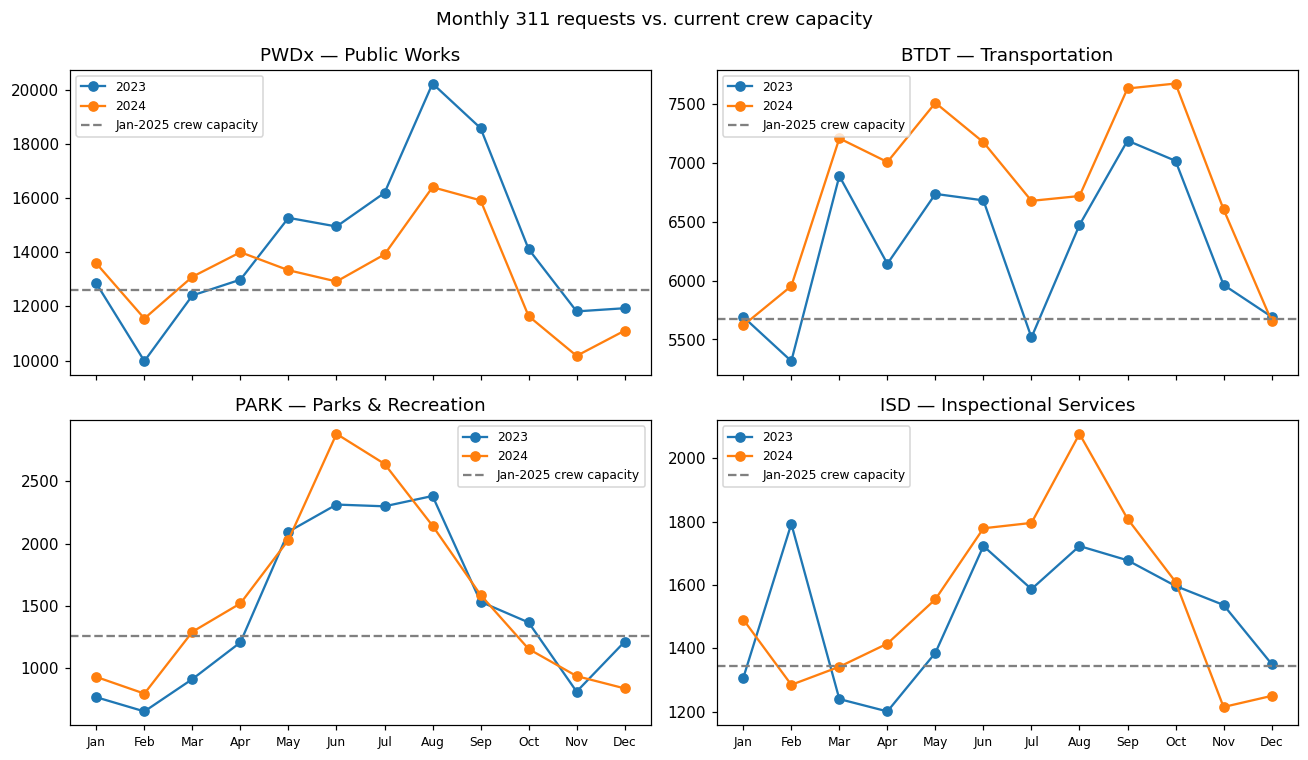

In [ ]:
monthly = df.groupby(["dept", "year", "month"]).size().rename("requests").reset_index()
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, d in zip(axes.flat, DEPTS):
    for yr in sorted(FILES):
        s = monthly[(monthly.dept == d) & (monthly.year == yr)].set_index("month")["requests"].reindex(MONTHS)
        ax.plot(MONTHS, s.values, marker="o", label=str(yr))
    cap = DEPTS[d]["jan_crews"] * DEPTS[d]["cap_month"]
    ax.axhline(cap, ls="--", c="grey", label="Jan-2025 crew capacity")
    ax.set_title(f"{d} — {DEPTS[d]['name']}"); ax.set_xticks(MONTHS); ax.set_xticklabels(MON, fontsize=8)
    ax.legend(fontsize=8)
fig.suptitle("Monthly 311 requests vs. current crew capacity"); fig.tight_layout()
fig.savefig(FIG_DIR / "monthly_requests.png"); plt.show()

In [ ]:
#On-time performance and SLA (target date) profile by department
ontime = df.pivot_table(index="dept", columns="year", values="is_ontime", aggfunc="mean").round(3)
d24 = df[df.year == 2024]
sla = d24.groupby("dept").agg(
    no_target_date=("has_sla", lambda s: 1 - s.mean()),
    median_target_days=("sla_days", "median"),
    target_le_30d=("sla_days", lambda s: (s <= 30).mean()),
    target_gt_90d=("sla_days", lambda s: (s > 90).mean()),
    median_days_to_close=("close_days", "median"),
).round(3)
display(ontime); display(sla)

year,2023,2024
dept,,
BTDT,0.652,0.499
ISD,0.744,0.724
PARK,0.868,0.932
PWDx,0.901,0.897


,no_target_date,median_target_days,target_le_30d,target_gt_90d,median_days_to_close
dept,,,,,
BTDT,0.020,1.614,0.958,0.003,1.025
ISD,0.004,30.000,0.306,0.396,2.820
PARK,0.022,365.000,0.405,0.571,2.106
PWDx,0.186,2.255,0.802,0.004,0.201


In [ ]:
#Who logs the requests? (city employees vs residents)
mix = (df.groupby(["dept", "source"]).size().rename("n").reset_index()
         .assign(share=lambda x: x.n / x.groupby("dept").n.transform("sum")))
mix.pivot(index="source", columns="dept", values="share").fillna(0).round(3)

dept,BTDT,ISD,PARK,PWDx
source,,,,
Citizens Connect App,0.339,0.118,0.302,0.205
City Worker App,0.013,0.007,0.201,0.151
Constituent Call,0.052,0.472,0.131,0.283
Employee Generated,0.591,0.368,0.353,0.308
Maximo Integration,0.000,0.000,0.000,0.000
Self Service,0.006,0.035,0.013,0.053


## 3. Demand forecast for 2025
Three candidate methods, compared on a **holdout**: train on 2023 + Jan–Aug 2024, predict Sep–Dec 2024.

* **Seasonal naive** — same month last year.
* **Seasonal × growth** — last year's month × the year-over-year growth seen so far.
* **Seasonal × damped growth** — same, but only half the growth is carried forward (guards against one-off jumps).

The method with the lowest average error is then used for 2025, with ±20% bands for the sensitivity analysis.

In [ ]:
hist = {d: (monthly[monthly.dept == d].pivot(index="year", columns="month", values="requests")
            .reindex(index=sorted(FILES), columns=MONTHS).fillna(0)) for d in DEPTS}

def mape(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    return float(np.mean(np.abs(a - f) / np.maximum(a, 1)))

clip = lambda g: float(np.clip(g, 0.8, 1.25))
rows = []
for d, h in hist.items():
    y23, y24 = h.loc[2023].values, h.loc[2024].values
    known, test = slice(0, 8), slice(8, 12)
    g = clip(y24[known].sum() / max(y23[known].sum(), 1))
    preds = {"seasonal_naive": y23[test],
             "seasonal_x_growth": y23[test] * g,
             "seasonal_x_damped_growth": y23[test] * (1 + 0.5 * (g - 1))}
    for m, p in preds.items():
        rows.append({"dept": d, "method": m, "MAPE_SepDec2024": mape(y24[test], p)})
bt = pd.DataFrame(rows).pivot(index="dept", columns="method", values="MAPE_SepDec2024")
bt.loc["AVERAGE"] = bt.mean()
BEST_METHOD = bt.loc["AVERAGE"].idxmin()
display(bt.round(3)); print("Chosen forecasting method:", BEST_METHOD)

method,seasonal_naive,seasonal_x_damped_growth,seasonal_x_growth
dept,,,
BTDT,0.062,0.042,0.036
ISD,0.107,0.122,0.142
PARK,0.200,0.226,0.270
PWDx,0.154,0.124,0.093
AVERAGE,0.131,0.129,0.135


Chosen forecasting method: seasonal_x_damped_growth


In [ ]:
#2025 forecast with the chosen method
fc_rows = []
for d, h in hist.items():
    y23, y24 = h.loc[2023].values, h.loc[2024].values
    shares = np.vstack([y23 / max(y23.sum(), 1), y24 / max(y24.sum(), 1)]).mean(axis=0)   # seasonal index
    g = clip(y24.sum() / max(y23.sum(), 1))
    if BEST_METHOD == "seasonal_naive":
        f = y24.astype(float)
    elif BEST_METHOD == "seasonal_x_growth":
        f = shares * y24.sum() * g
    else:
        f = shares * y24.sum() * (1 + 0.5 * (g - 1))
    for m in MONTHS:
        fc_rows.append({"dept": d, "month": m, "forecast": round(f[m - 1]),
                        "low_-20%": round(0.8 * f[m - 1]), "high_+20%": round(1.2 * f[m - 1])})
forecast = pd.DataFrame(fc_rows)
FC = {d: forecast[forecast.dept == d].sort_values("month")["forecast"].to_numpy(float) for d in DEPTS}

display(forecast.pivot(index="month", columns="dept", values="forecast").rename(index=dict(zip(MONTHS, MON))))
print(forecast.groupby("dept")["forecast"].sum().rename("2025 total forecast"))
forecast.to_csv(OUT_DIR / "forecast_2025.csv", index=False)

dept,BTDT,ISD,PARK,PWDx
month,,,,
Jan,6127,1437,902,12194
Feb,6090,1585,770,9953
Mar,7628,1326,1171,11764
Apr,7104,1343,1451,12456
May,7700,1510,2206,13145
Jun,7494,1799,2767,12804
Jul,6580,1737,2635,13832
Aug,7139,1950,2423,16807
Sep,8018,1791,1667,15846


dept
BTDT     84765
ISD      18880
PARK     19375
PWDx    151325
Name: 2025 total forecast, dtype: int64


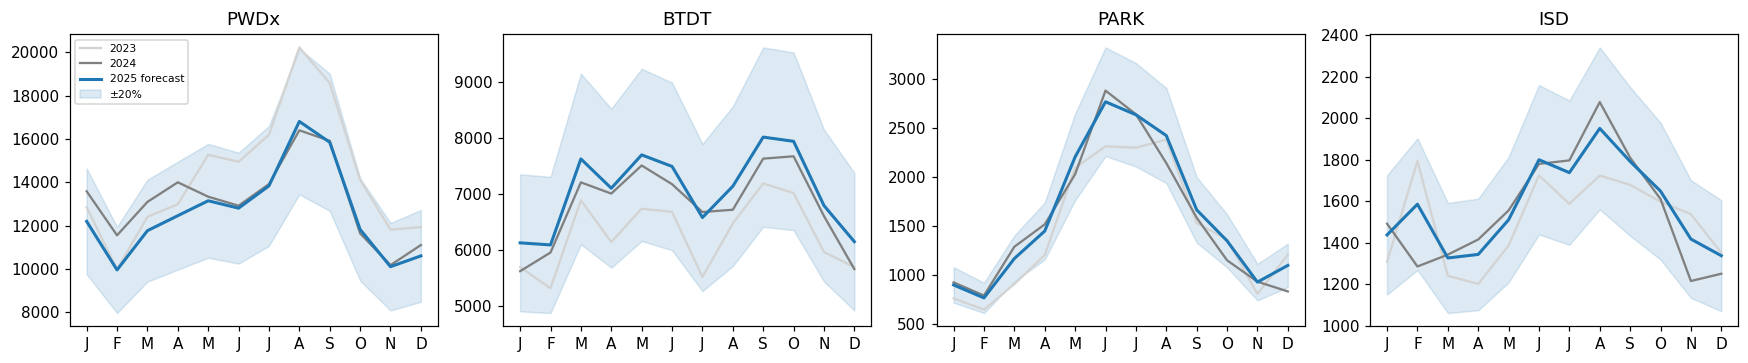

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, d in zip(axes, DEPTS):
    ax.plot(MONTHS, hist[d].loc[2023], c="lightgrey", label="2023")
    ax.plot(MONTHS, hist[d].loc[2024], c="grey", label="2024")
    ax.plot(MONTHS, FC[d], c="C0", lw=2, label="2025 forecast")
    ax.fill_between(MONTHS, 0.8 * FC[d], 1.2 * FC[d], alpha=.15, color="C0", label="±20%")
    ax.set_title(d); ax.set_xticks(MONTHS); ax.set_xticklabels([m[0] for m in MON])
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG_DIR / "forecast_2025.png"); plt.show()

## 4. Dynamic staffing model
**Simulation (monthly, per department).**
* Each month's forecast requests arrive. Each request gets a target date drawn from the department's real 2024 target-date profile
  (bucketed into "due this month", "due next month", … and "no target date").
* Capacity = (permanent crews + seasonal crews) × daily capacity × 21 days.
* Crews work the queue **oldest first** (by arrival month), most urgent first within a month. A request still open at the end of its due month is **overdue** (\$20);
  if it is still open one month later (≈30 days past target) it costs **another \$100**. No backlog at the start of 2025.
* Requests still open on 31 Dec 2025 carry a \$20 **carry-over cost** each, so the optimiser can't "win" by letting a backlog pile up late in the year.

**Costs.** Crew-months × annual cost/12; a new crew is paid during its 1 training month (no capacity); a release costs 25% of annual cost
and the crew works its 1-month notice; Parks seasonal crews (Apr–Oct) cost 1.3× with no delay or release cost. January 2025 is fixed at the given crew levels.

**Optimisation.** Multi-start local search over the 12-month crew vector (single-month and block moves of ±1, ±2, ±5 crews, plus Parks seasonal crews),
minimising total cost = staffing + hiring/release + overdue penalties. We produce two plans:
1. **Cost-optimal** — pure brief economics.
2. **Recommended** — cost-optimal subject to a service floor (modelled on-time rate ≥ `SERVICE_FLOOR`).

In [ ]:
NO_DUE = 10**6

def sla_profile(sub):
    """Share of requests by 'grace months' (0 = due in arrival month, 1 = next month, ...); None = no target date."""
    n = len(sub)
    ok = sub["has_sla"]
    prof = {None: float((~ok).sum() / n)}
    g = np.clip(np.ceil(sub.loc[ok, "sla_days"].clip(lower=0.01) / 30.4) - 1, 0, 12).astype(int)
    for k, v in g.value_counts().items():
        prof[int(k)] = float(v / n)
    return prof

SLA_PROFILE = {d: sla_profile(df[(df.dept == d) & (df.year == 2024)]) for d in DEPTS}
pd.DataFrame({d: {("none" if k is None else f"{k} mo"): round(v, 3) for k, v in p.items()}
              for d, p in SLA_PROFILE.items()}).fillna(0)

,PWDx,BTDT,PARK,ISD
none,0.186,0.020,0.022,0.004
0 mo,0.804,0.968,0.406,0.575
1 mo,0.006,0.009,0.000,0.015
12 mo,0.002,0.001,0.570,0.083
3 mo,0.001,0.000,0.000,0.251
5 mo,0.000,0.002,0.000,0.004
2 mo,0.000,0.000,0.000,0.067
9 mo,0.000,0.000,0.000,0.000
10 mo,0.000,0.000,0.000,0.000
4 mo,0.000,0.000,0.000,0.000


In [ ]:
def simulate(dept, demand, crews, seasonal=None, workload_share=WORKLOAD_SHARE, detail=False):
    p, prof = DEPTS[dept], SLA_PROFILE[dept]
    seasonal = list(seasonal) if seasonal is not None else [0] * 12
    open_q, overdue, long_overdue, sla_total, served_tot = {}, 0.0, 0.0, 0.0, 0.0
    rows = []
    for m in range(12):
        arr = demand[m] * workload_share
        for g, sh in prof.items():
            due = NO_DUE if g is None else m + g
            open_q[(due, m)] = open_q.get((due, m), 0.0) + arr * sh
            if g is not None:
                sla_total += arr * sh
        cap = (crews[m] + seasonal[m]) * p["cap_month"]
        served = 0.0
        for key in sorted(open_q, key=lambda k: (k[1], k[0])):   # oldest arrival first, then earliest due
            if cap <= 0:
                break
            take = min(cap, open_q[key]); open_q[key] -= take; cap -= take; served += take
        open_q = {k: v for k, v in open_q.items() if v > 1e-9}
        od = sum(v for (due, _), v in open_q.items() if due == m)          # just missed target
        lod = sum(v for (due, _), v in open_q.items() if due == m - 1)     # 30+ days past target
        overdue += od; long_overdue += lod; served_tot += served
        if detail:
            rows.append({"month": m + 1, "demand": arr, "capacity": (crews[m] + seasonal[m]) * p["cap_month"],
                         "served": served, "new_overdue": od, "new_30d_overdue": lod,
                         "backlog_end": sum(open_q.values())})
    out = {"overdue": overdue, "long_overdue": long_overdue,
           "penalty": overdue * OVERDUE_COST + long_overdue * LONG_OVERDUE_COST,
           "on_time_rate": 1 - overdue / max(sla_total, 1), "backlog_end": sum(open_q.values()),
           "utilisation": served_tot / max(sum((c + s) * p["cap_month"] for c, s in zip(crews, seasonal)), 1)}
    if detail:
        out["monthly"] = pd.DataFrame(rows)
    return out

def staffing_cost(dept, crews, seasonal=None):
    p = DEPTS[dept]; seasonal = seasonal if seasonal is not None else [0] * 12
    assert crews[0] == p["jan_crews"], "January 2025 crews are fixed by the brief"
    labour = sum(crews) * p["cost_month"]
    hires = releases = 0
    for m in range(1, 12):
        diff = crews[m] - crews[m - 1]
        hires += max(diff, 0); releases += max(-diff, 0)
    training = hires * p["cost_month"]                     # paid during the 1-month training
    severance = releases * RELEASE_COST_SHARE * p["annual_cost"]
    seas = sum(seasonal) * p["cost_month"] * SEASONAL_COST_MULT
    return {"labour": labour, "training": training, "release": severance, "seasonal": seas,
            "hires": hires, "releases": releases}

def evaluate(dept, demand, crews, seasonal=None, workload_share=WORKLOAD_SHARE, floor=None):
    s = simulate(dept, demand, crews, seasonal, workload_share)
    c = staffing_cost(dept, crews, seasonal)
    carry = s["backlog_end"] * CARRYOVER_COST
    total = c["labour"] + c["training"] + c["release"] + c["seasonal"] + s["penalty"] + carry
    obj = total + (5e6 * max(0.0, floor - s["on_time_rate"]) if floor else 0.0)
    return {**c, **s, "carryover": carry, "total_cost": total, "objective": obj}

In [ ]:
def optimize(dept, demand, workload_share=WORKLOAD_SHARE, floor=None, max_passes=25, max_mult=3, init=None):
    """Local search. Returns (permanent crews per month, seasonal crews per month). Heuristic, not guaranteed optimal."""
    p = DEPTS[dept]
    cap_max = int(max_mult * p["jan_crews"]) + 5
    need = [min(cap_max, math.ceil(d * workload_share / p["cap_month"])) for d in demand]
    crews, seas = (list(init[0]), list(init[1])) if init else ([p["jan_crews"]] + need[1:], [0] * 12)
    seas_idx = [m - 1 for m in SEASONAL_MONTHS] if dept == SEASONAL_DEPT else []
    f = lambda c, s: evaluate(dept, demand, c, s, workload_share, floor)["objective"]
    best = f(crews, seas)
    for _ in range(max_passes):
        improved = False
        for i in range(1, 12):
            for j in range(i, 12):
                for dl in (-5, -2, -1, 1, 2, 5):
                    c = crews[:i] + [min(cap_max, max(0, x + dl)) for x in crews[i:j + 1]] + crews[j + 1:]
                    if c == crews:
                        continue
                    v = f(c, seas)
                    if v < best - 1e-6:
                        best, crews, improved = v, c, True
        for i in seas_idx:
            for j in [x for x in seas_idx if x >= i]:
                for dl in (-2, -1, 1, 2):
                    s = seas[:i] + [max(0, x + dl) for x in seas[i:j + 1]] + seas[j + 1:]
                    if s == seas:
                        continue
                    v = f(crews, s)
                    if v < best - 1e-6:
                        best, seas, improved = v, s, True
                for dl in (1, 2, 4):                 # swap permanent crews for seasonal crews in a block
                    s = seas[:i] + [x + dl for x in seas[i:j + 1]] + seas[j + 1:]
                    c = crews[:i] + [max(0, x - dl) for x in crews[i:j + 1]] + crews[j + 1:]
                    v = f(c, s)
                    if v < best - 1e-6:
                        best, crews, seas, improved = v, c, s, True
        if not improved:
            break
    return crews, seas

In [ ]:
#Build the three plans per department
t0 = time.time()
PLANS = {}
for d in DEPTS:
    sq = [DEPTS[d]["jan_crews"]] * 12
    PLANS[(d, "Status quo")] = (sq, [0] * 12)
    # several starting points, keep the best (local search can stop in a local optimum)
    starts = [None, (sq, [0] * 12)]
    obj = lambda cs, fl: evaluate(d, FC[d], *cs, floor=fl)["objective"]
    co = min((optimize(d, FC[d], init=st) for st in starts), key=lambda cs: obj(cs, None))
    rec = min((optimize(d, FC[d], floor=SERVICE_FLOOR, init=st) for st in starts + [co]), key=lambda cs: obj(cs, SERVICE_FLOOR))
    if obj(rec, None) < obj(co, None):          # a service-floor plan that is also cheaper is the better cost plan
        co = rec
    PLANS[(d, "Cost-optimal")], PLANS[(d, "Recommended")] = co, rec
print(f"optimised in {time.time() - t0:.1f}s")

summ = []
for (d, name), (c, s) in PLANS.items():
    e = evaluate(d, FC[d], c, s)
    summ.append({"dept": d, "plan": name, "avg_crews": np.mean(c), "seasonal_crew_months": sum(s),
                 "hires": e["hires"], "releases": e["releases"], "staff_cost": e["labour"] + e["training"] + e["seasonal"],
                 "release_cost": e["release"], "overdue_penalty": e["penalty"], "year_end_carryover": e["carryover"],
                 "total_cost": e["total_cost"],
                 "on_time_modelled": e["on_time_rate"], "year_end_backlog": e["backlog_end"]})
plan_summary = pd.DataFrame(summ)
tot = plan_summary.groupby("plan")[["staff_cost", "release_cost", "overdue_penalty", "year_end_carryover", "total_cost"]].sum()
display(plan_summary.round({"avg_crews": 1, "on_time_modelled": 3, "year_end_backlog": 0,
                            "staff_cost": 0, "overdue_penalty": 0, "year_end_carryover": 0, "total_cost": 0}))
display(tot.round(0))

optimised in 25.4s


,dept,plan,avg_crews,seasonal_crew_months,hires,releases,staff_cost,release_cost,overdue_penalty,year_end_carryover,total_cost,on_time_modelled,year_end_backlog
0,PWDx,Status quo,50.0,0,0,0,6500000.0,0.0,436713.0,83160.0,7019873.0,0.823,4158.0
1,PWDx,Cost-optimal,51.2,0,2,0,6684167.0,0.0,194012.0,7700.0,6885879.0,0.921,385.0
2,PWDx,Recommended,51.2,0,2,0,6684167.0,0.0,194012.0,7700.0,6885879.0,0.921,385.0
3,BTDT,Status quo,18.0,0,0,0,1980000.0,0.0,4422181.0,334500.0,6736681.0,0.246,16725.0
4,BTDT,Cost-optimal,22.4,0,5,0,2511667.0,0.0,94570.0,1960.0,2608197.0,0.943,98.0
5,BTDT,Recommended,22.4,0,5,0,2511667.0,0.0,94570.0,1960.0,2608197.0,0.943,98.0
6,PARK,Status quo,10.0,0,0,0,1200000.0,0.0,468403.0,103840.0,1772243.0,0.730,5192.0
7,PARK,Cost-optimal,1.0,0,0,10,120000.0,300000.0,827603.0,364420.0,1612023.0,0.616,18221.0
8,PARK,Recommended,12.6,7,4,0,1641000.0,0.0,56736.0,9300.0,1707036.0,0.850,465.0
9,ISD,Status quo,16.0,0,0,0,2240000.0,0.0,283290.0,55040.0,2578330.0,0.707,2752.0


,staff_cost,release_cost,overdue_penalty,year_end_carryover,total_cost
plan,,,,,
Cost-optimal,11672500.0,300000.0,1212380.0,414000.0,13598880.0
Recommended,13321833.0,0.0,400403.0,42080.0,13764316.0
Status quo,11920000.0,0.0,5610588.0,576540.0,18107128.0


In [ ]:
#The recommended month-by-month plan, with the action to take in each month
def plan_table(d, plan="Recommended"):
    c, s = PLANS[(d, plan)]
    sim = simulate(d, FC[d], c, s, detail=True)["monthly"]
    rows = []
    for m in range(12):
        acts = []
        if m < 11 and c[m + 1] > c[m]:
            acts.append(f"Start hiring/training {c[m+1]-c[m]} crew(s) → active {MON[m+1]}")
        if m < 11 and c[m + 1] < c[m]:
            acts.append(f"Give notice to {c[m]-c[m+1]} crew(s) → leave end of {MON[m]}")
        if m > 0 and s[m] > s[m - 1] or (m == 0 and s[0] > 0):
            acts.append(f"Start {s[m]-(s[m-1] if m else 0)} seasonal crew(s)")
        if m > 0 and s[m] < s[m - 1]:
            acts.append(f"End {s[m-1]-s[m]} seasonal crew(s)")
        rows.append({"dept": d, "month": MON[m], "permanent_crews": c[m], "seasonal_crews": s[m],
                     "capacity": int(sim.capacity[m]), "forecast_requests": int(FC[d][m]),
                     "utilisation": min(1.0, sim.served[m] / max(sim.capacity[m], 1)),
                     "backlog_end": int(sim.backlog_end[m]), "action_this_month": "; ".join(acts)})
    return pd.DataFrame(rows)

staffing_plan = pd.concat([plan_table(d) for d in DEPTS], ignore_index=True)
staffing_plan.to_csv(OUT_DIR / "staffing_plan_2025.csv", index=False)
crew_grid = staffing_plan.pivot(index="month", columns="dept", values="permanent_crews").reindex(MON)
crew_grid["PARK_seasonal"] = staffing_plan[staffing_plan.dept == "PARK"].set_index("month")["seasonal_crews"].reindex(MON)
display(crew_grid)
for d in DEPTS:
    print(f"\n=== {d} — {DEPTS[d]['name']} ===")
    display(plan_table(d).drop(columns="dept").round(2))

dept,BTDT,ISD,PARK,PWDx,PARK_seasonal
month,,,,,
Jan,18,16,10,50,0
Feb,21,16,10,50,0
Mar,23,17,10,50,0
Apr,23,18,10,50,2
May,23,18,13,51,1
Jun,23,18,14,52,2
Jul,23,18,14,52,2
Aug,23,18,14,52,0
Sep,23,18,14,52,0



=== PWDx — Public Works ===


,month,permanent_crews,seasonal_crews,capacity,forecast_requests,utilisation,backlog_end,action_this_month
0,Jan,50,0,12600,12194,0.97,0,
1,Feb,50,0,12600,9953,0.79,0,
2,Mar,50,0,12600,11764,0.93,0,
3,Apr,50,0,12600,12456,0.99,0,Start hiring/training 1 crew(s) → active May
4,May,51,0,12852,13145,1.00,293,Start hiring/training 1 crew(s) → active Jun
5,Jun,52,0,13104,12804,1.00,0,
6,Jul,52,0,13104,13832,1.00,728,
7,Aug,52,0,13104,16807,1.00,4430,
8,Sep,52,0,13104,15846,1.00,7172,
9,Oct,52,0,13104,11822,1.00,5891,



=== BTDT — Transportation ===


,month,permanent_crews,seasonal_crews,capacity,forecast_requests,utilisation,backlog_end,action_this_month
0,Jan,18,0,5670,6127,1.00,457,Start hiring/training 3 crew(s) → active Feb
1,Feb,21,0,6615,6090,0.99,0,Start hiring/training 2 crew(s) → active Mar
2,Mar,23,0,7245,7628,1.00,383,
3,Apr,23,0,7245,7104,1.00,241,
4,May,23,0,7245,7700,1.00,697,
5,Jun,23,0,7245,7494,1.00,946,
6,Jul,23,0,7245,6580,1.00,281,
7,Aug,23,0,7245,7139,1.00,175,
8,Sep,23,0,7245,8018,1.00,948,
9,Oct,23,0,7245,7943,1.00,1646,



=== PARK — Parks & Recreation ===


,month,permanent_crews,seasonal_crews,capacity,forecast_requests,utilisation,backlog_end,action_this_month
0,Jan,10,0,1260,902,0.72,0,
1,Feb,10,0,1260,770,0.61,0,
2,Mar,10,0,1260,1171,0.93,0,
3,Apr,10,2,1512,1451,0.96,0,Start hiring/training 3 crew(s) → active May; Start 2 seasonal crew(s)
4,May,13,1,1764,2206,1.00,442,Start hiring/training 1 crew(s) → active Jun; End 1 seasonal crew(s)
5,Jun,14,2,2016,2767,1.00,1193,Start 1 seasonal crew(s)
6,Jul,14,2,2016,2635,1.00,1812,
7,Aug,14,0,1764,2423,1.00,2471,End 2 seasonal crew(s)
8,Sep,14,0,1764,1667,1.00,2374,
9,Oct,14,0,1764,1351,1.00,1961,



=== ISD — Inspectional Services ===


,month,permanent_crews,seasonal_crews,capacity,forecast_requests,utilisation,backlog_end,action_this_month
0,Jan,16,0,1344,1437,1.0,93,
1,Feb,16,0,1344,1585,1.0,334,Start hiring/training 1 crew(s) → active Mar
2,Mar,17,0,1428,1326,1.0,231,Start hiring/training 1 crew(s) → active Apr
3,Apr,18,0,1512,1343,1.0,62,
4,May,18,0,1512,1510,1.0,60,
5,Jun,18,0,1512,1799,1.0,347,
6,Jul,18,0,1512,1737,1.0,573,
7,Aug,18,0,1512,1950,1.0,1010,
8,Sep,18,0,1512,1791,1.0,1290,
9,Oct,18,0,1512,1648,1.0,1426,


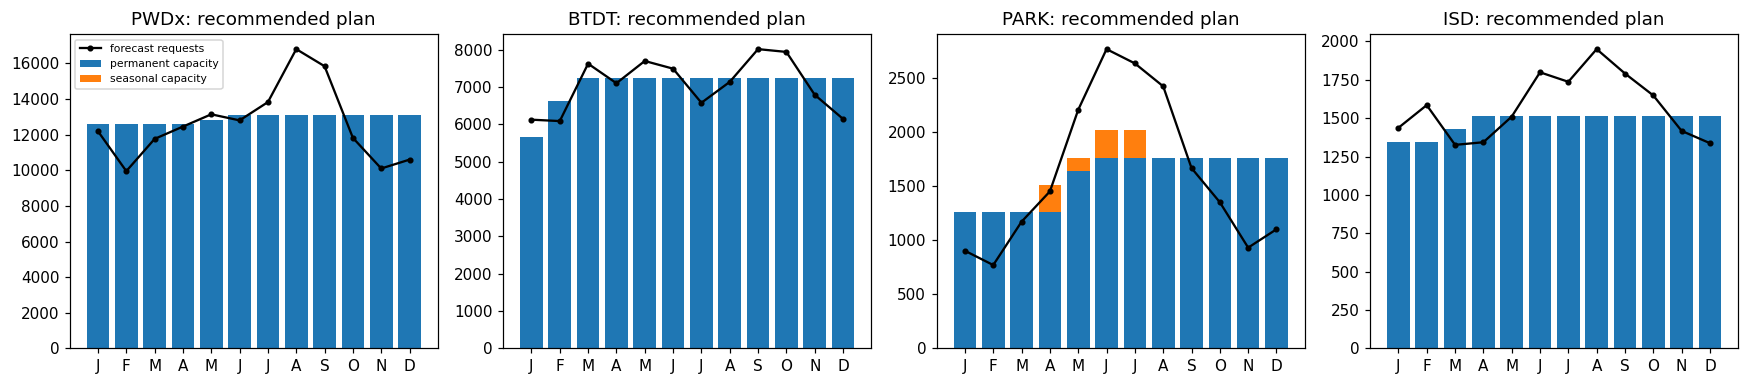

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, d in zip(axes, DEPTS):
    t = plan_table(d)
    ax.bar(MONTHS, t.permanent_crews * DEPTS[d]["cap_month"], label="permanent capacity")
    ax.bar(MONTHS, t.seasonal_crews * DEPTS[d]["cap_month"], bottom=t.permanent_crews * DEPTS[d]["cap_month"],
           label="seasonal capacity")
    ax.plot(MONTHS, FC[d], "k-o", ms=3, label="forecast requests")
    ax.set_title(f"{d}: recommended plan"); ax.set_xticks(MONTHS); ax.set_xticklabels([m[0] for m in MON])
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG_DIR / "recommended_plan.png"); plt.show()

### 4.1 Model check against 2024 reality
We replay **actual 2024 demand** through the simulator with the January-2025 crew levels and compare the modelled on-time rate
with the real 2024 on-time rate. A large gap means the brief's crew-capacity numbers do not describe all of the work
(for example many employee-logged requests are closed without a crew visit). We keep the brief's numbers but report the gap and test a lower workload share in §5.

In [ ]:
cal = []
for d in DEPTS:
    actual = hist[d].loc[2024].to_numpy(float)
    for ws in (1.0, 0.8, 0.6):
        e = evaluate(d, actual, [DEPTS[d]["jan_crews"]] * 12, workload_share=ws)
        cal.append({"dept": d, "workload_share": ws, "modelled_on_time": e["on_time_rate"],
                    "actual_on_time_2024": df[(df.dept == d) & (df.year == 2024)]["is_ontime"].mean()})
calibration = pd.DataFrame(cal).pivot(index="dept", columns="workload_share", values="modelled_on_time")
calibration["actual_2024"] = pd.DataFrame(cal).groupby("dept")["actual_on_time_2024"].first()
calibration.round(3)

workload_share,0.6,0.8,1.0,actual_2024
dept,,,,
BTDT,1.000,0.973,0.302,0.499
ISD,1.000,1.000,0.725,0.724
PARK,0.995,0.791,0.741,0.932
PWDx,1.000,1.000,0.739,0.897


### 4.2 Break-even economics (why the optimiser behaves as it does)

In [ ]:
be = pd.DataFrame({d: {"crew_cost_per_month": p["cost_month"], "requests_per_crew_month": p["cap_month"],
                       "cost_per_request_served": p["cost_month"] / p["cap_month"],
                       "penalty_if_overdue": OVERDUE_COST,
                       "penalty_if_30d_overdue": OVERDUE_COST + LONG_OVERDUE_COST} for d, p in DEPTS.items()}).T
be["when_hiring_pays_for_itself"] = np.where(
    be.cost_per_request_served <= OVERDUE_COST, "whenever a request would otherwise go overdue",
    np.where(be.cost_per_request_served <= OVERDUE_COST + LONG_OVERDUE_COST,
             "only when requests would otherwise go 30+ days overdue", "never on penalty cost alone (a service target is needed)"))
be.round(1)

,crew_cost_per_month,requests_per_crew_month,cost_per_request_served,penalty_if_overdue,penalty_if_30d_overdue,when_hiring_pays_for_itself
PWDx,10833.3,252.0,43.0,20.0,120.0,only when requests would otherwise go 30+ days overdue
BTDT,9166.7,315.0,29.1,20.0,120.0,only when requests would otherwise go 30+ days overdue
PARK,10000.0,126.0,79.4,20.0,120.0,only when requests would otherwise go 30+ days overdue
ISD,11666.7,84.0,138.9,20.0,120.0,never on penalty cost alone (a service target is needed)


## 5. Sensitivity analysis
For each scenario we report (a) the **recommended plan kept fixed** (what happens if reality differs from the forecast and we can't react,
since hiring takes a month) and (b) a **re-optimised plan** with perfect foresight that still respects the service floor.
`cost_change_if_replanned` < 0 means re-planning saves money; > 0 means extra spend is needed to get back above the service floor.

In [ ]:
SCENARIOS = {
    "Base": {},
    "Demand −20%": {"all": 0.8},
    "Demand +20%": {"all": 1.2},
    "Snowstorm (Feb: PWD +60%, BTD +40%)": {"months": {2: {"PWDx": 1.6, "BTDT": 1.4}}},
    "Heat wave (Jul: Parks +40%, ISD +30%, PWD +15%)": {"months": {7: {"PARK": 1.4, "ISD": 1.3, "PWDx": 1.15}}},
}
def scenario_demand(d, sc):
    x = FC[d] * sc.get("all", 1.0)
    for m, mult in sc.get("months", {}).items():
        x = x.copy(); x[m - 1] *= mult.get(d, 1.0)
    return x

sens = []
for name, sc in SCENARIOS.items():
    for d in DEPTS:
        dem = scenario_demand(d, sc)
        c, s = PLANS[(d, "Recommended")]
        fixed = evaluate(d, dem, c, s)
        rc, rs = optimize(d, dem, floor=SERVICE_FLOOR, max_passes=10) if name != "Base" else (c, s)
        reopt = evaluate(d, dem, rc, rs)
        sens.append({"scenario": name, "dept": d, "fixed_plan_cost": fixed["total_cost"],
                     "fixed_plan_on_time": fixed["on_time_rate"], "reoptimised_cost": reopt["total_cost"],
                     "reoptimised_on_time": reopt["on_time_rate"],
                     "cost_change_if_replanned": reopt["total_cost"] - fixed["total_cost"]})
sensitivity = pd.DataFrame(sens)
sens_tot = sensitivity.groupby("scenario", sort=False)[["fixed_plan_cost", "reoptimised_cost", "cost_change_if_replanned"]].sum()
display(sensitivity.round({"fixed_plan_cost": 0, "reoptimised_cost": 0, "cost_change_if_replanned": 0,
                           "fixed_plan_on_time": 3, "reoptimised_on_time": 3}))
display(sens_tot.round(0))
sensitivity.to_csv(OUT_DIR / "sensitivity.csv", index=False)

,scenario,dept,fixed_plan_cost,fixed_plan_on_time,reoptimised_cost,reoptimised_on_time,cost_change_if_replanned
0,Base,PWDx,6885879.0,0.921,6885879.0,0.921,0.0
1,Base,BTDT,2608197.0,0.943,2608197.0,0.943,0.0
2,Base,PARK,1707036.0,0.850,1707036.0,0.850,0.0
3,Base,ISD,2563204.0,0.854,2563204.0,0.854,0.0
4,Demand −20%,PWDx,6684167.0,1.000,5930435.0,0.932,-753732.0
5,Demand −20%,BTDT,2511667.0,1.000,2098871.0,0.986,-412795.0
6,Demand −20%,PARK,1641000.0,1.000,1399627.0,0.853,-241373.0
7,Demand −20%,ISD,2485000.0,1.000,2193531.0,0.854,-291469.0
8,Demand +20%,PWDx,12509980.0,0.398,8160275.0,0.933,-4349706.0
9,Demand +20%,BTDT,7480374.0,0.209,3176335.0,0.952,-4304039.0


,fixed_plan_cost,reoptimised_cost,cost_change_if_replanned
scenario,,,
Base,13764316.0,13764316.0,0.0
Demand −20%,13321833.0,11622464.0,-1699369.0
Demand +20%,25403772.0,16578201.0,-8825571.0
"Snowstorm (Feb: PWD +60%, BTD +40%)",14587374.0,14133223.0,-454151.0
"Heat wave (Jul: Parks +40%, ISD +30%, PWD +15%)",14206025.0,14260452.0,54427.0


workload_share,0.6,0.8,1.0
dept,,,
BTDT,14.3,18.8,23.1
ISD,11.4,14.6,18.2
PARK,7.2,10.0,11.3
PWDx,32.6,42.2,51.2


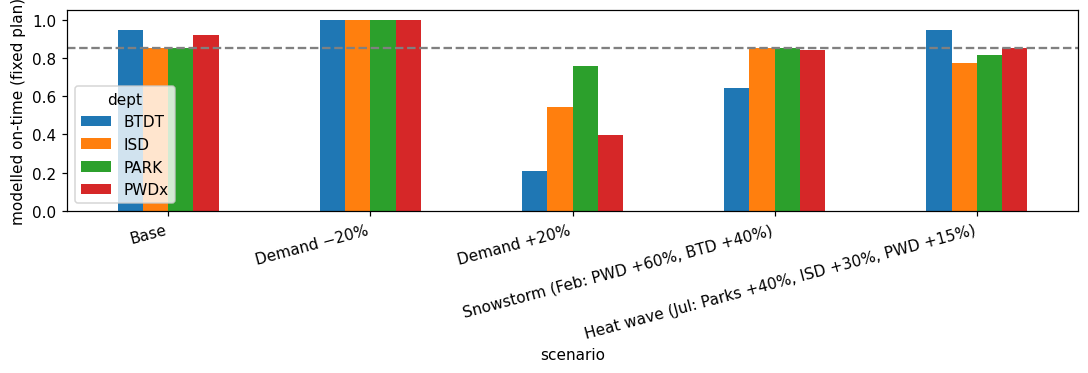

In [ ]:
#Workload-share sensitivity (what if only part of the requests need a crew visit?)
ws_rows = []
for ws in (1.0, 0.8, 0.6):
    for d in DEPTS:
        c, s = optimize(d, FC[d], workload_share=ws, floor=SERVICE_FLOOR, max_passes=10)
        e = evaluate(d, FC[d], c, s, workload_share=ws)
        ws_rows.append({"workload_share": ws, "dept": d, "avg_crews": np.mean(c), "total_cost": e["total_cost"],
                        "on_time": e["on_time_rate"]})
ws_tbl = pd.DataFrame(ws_rows)
display(ws_tbl.pivot(index="dept", columns="workload_share", values="avg_crews").round(1))

ax = sensitivity.pivot(index="scenario", columns="dept", values="fixed_plan_on_time").loc[list(SCENARIOS)].plot.bar(figsize=(10, 3.5))
ax.axhline(SERVICE_FLOOR, ls="--", c="grey"); ax.set_ylabel("modelled on-time (fixed plan)")
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.savefig(FIG_DIR / "sensitivity.png"); plt.show()

## 6. Other considerations
### 6.1 Neighborhood equity in response times (2024)

In [ ]:
eq = (d24[d24.neighborhood != ""].groupby(["dept", "neighborhood"])
      .agg(n=("case_enquiry_id", "size"), on_time=("is_ontime", "mean"), median_days_to_close=("close_days", "median"))
      .reset_index())
eq = eq[eq.n >= 200]
eq_gap = eq.groupby("dept").agg(best_on_time=("on_time", "max"), worst_on_time=("on_time", "min"),
                                 gap_pts=("on_time", lambda s: s.max() - s.min()), neighborhoods=("n", "size"))
display(eq_gap.round(3))
for d in DEPTS:
    e = eq[eq.dept == d].sort_values("on_time")
    if len(e):
        print(f"\n{d}: 5 neighborhoods with the LOWEST on-time rate")
        display(e.head(5).round(3))
eq.to_csv(OUT_DIR / "equity_by_neighborhood.csv", index=False)

,best_on_time,worst_on_time,gap_pts,neighborhoods
dept,,,,
BTDT,0.622,0.365,0.257,21
ISD,0.777,0.624,0.154,20
PARK,0.982,0.893,0.090,20
PWDx,0.943,0.804,0.139,22



PWDx: 5 neighborhoods with the LOWEST on-time rate


,dept,neighborhood,n,on_time,median_days_to_close
75,PWDx,Charlestown,3909,0.804,0.451
80,PWDx,Fenway / Kenmore / Audubon Circle / Longwood,1877,0.847,0.371
74,PWDx,Brighton,827,0.851,0.180
73,PWDx,Boston,4125,0.860,0.139
71,PWDx,Back Bay,8588,0.873,0.117



BTDT: 5 neighborhoods with the LOWEST on-time rate


,dept,neighborhood,n,on_time,median_days_to_close
22,BTDT,West Roxbury,1678,0.365,4.220
14,BTDT,Jamaica Plain,5566,0.392,2.971
13,BTDT,Hyde Park,2027,0.394,4.275
17,BTDT,Roslindale,2736,0.425,3.021
6,BTDT,Charlestown,3541,0.426,1.522



PARK: 5 neighborhoods with the LOWEST on-time rate


,dept,neighborhood,n,on_time,median_days_to_close
50,PARK,Boston,1296,0.893,0.989
57,PARK,Fenway / Kenmore / Audubon Circle / Longwood,337,0.899,1.738
60,PARK,Jamaica Plain,1177,0.908,1.934
52,PARK,Charlestown,686,0.911,4.692
48,PARK,Back Bay,428,0.911,2.086



ISD: 5 neighborhoods with the LOWEST on-time rate


,dept,neighborhood,n,on_time,median_days_to_close
35,ISD,Greater Mattapan,967,0.624,4.559
33,ISD,East Boston,1153,0.645,3.495
36,ISD,Hyde Park,673,0.672,3.018
32,ISD,Downtown / Financial District,813,0.697,2.762
34,ISD,Fenway / Kenmore / Audubon Circle / Longwood,416,0.702,4.000


### 6.2 Requests from city employees vs residents

In [ ]:
src = (d24.groupby(["dept", "source_group"])
       .agg(n=("case_enquiry_id", "size"), on_time=("is_ontime", "mean"), median_days_to_close=("close_days", "median"))
       .reset_index())
src["share"] = src.n / src.groupby("dept").n.transform("sum")
display(src.round(3))
print("Most common closure reasons (first 70 chars):")
cr = (d24.assign(cr=d24.closure_reason.str.slice(0, 70)).groupby(["dept", "cr"]).size()
      .rename("n").reset_index().sort_values(["dept", "n"], ascending=[True, False]).groupby("dept").head(4))
display(cr)

,dept,source_group,n,on_time,median_days_to_close,share
0,BTDT,City employee,50182,0.501,0.883,0.616
1,BTDT,Resident,31265,0.497,1.635,0.384
2,ISD,City employee,7502,0.747,2.223,0.403
3,ISD,Resident,11122,0.709,3.242,0.597
4,PARK,City employee,11307,0.950,2.839,0.603
5,PARK,Resident,7429,0.904,1.892,0.397
6,PWDx,City employee,78174,0.896,0.121,0.496
7,PWDx,Resident,79436,0.898,0.529,0.504


Most common closure reasons (first 70 chars):


,dept,cr,n
0,BTDT,,16316
22,BTDT,Case Closed Case Resolved,8
27,BTDT,Case Closed Case Resolved This vehicle is not at location,7
1,BTDT,Case Closed Case Noted,6
65107,ISD,,1943
72837,ISD,Case Closed. Closed date : Mon Feb 10 12:58:39 EST 2025 Noted Building,2
65108,ISD,Case Closed. Closed date : 2024-01-02 04:50:51.013 Case Noted area ins,1
65109,ISD,Case Closed. Closed date : 2024-01-02 04:52:00.947 Case Noted area ins,1
82148,PARK,Case Closed Case Resolved The tree was pruned by Northern Tree Service,556
81788,PARK,,119


## 7. GenAI application: 311 Intake Assistant
A resident types a problem in plain English. The assistant:
1. **Retrieves** the closest real request types from a catalog built from the data (**RAG**, OpenAI embeddings);
2. Asks the LLM to choose among those candidates with a **structured (Pydantic) output** and a carefully engineered prompt (**prompt engineering**);
3. Returns `request_type`, `department`, `queue` — always a real combination from the data, never an invented one;
4. Asks **one follow-up question** when the message is too vague.

Supporting LLM steps: cleaning/grouping messy `case_title` values (§7.3) and writing plain-language descriptions for each type to improve retrieval (§7.4).

### 7.1 LLM helpers (structured output + usage tracking)

In [ ]:
from pydantic import BaseModel, Field

USAGE = {"calls": 0, "prompt_tokens": 0, "completion_tokens": 0}

def _track(resp):
    USAGE["calls"] += 1
    u = getattr(resp, "usage", None)
    if u is not None:
        USAGE["prompt_tokens"] += getattr(u, "prompt_tokens", 0) or 0
        USAGE["completion_tokens"] += getattr(u, "completion_tokens", 0) or 0

def llm_parse(messages, schema, model=None, temperature=0):
    """Call the chat model and return a validated Pydantic object (structured output)."""
    model = model or LLM_MODEL
    last = None
    for attempt in range(3):
        try:
            parse = getattr(client.chat.completions, "parse", None) or client.beta.chat.completions.parse
            resp = parse(model=model, messages=messages, response_format=schema, temperature=temperature)
            _track(resp)
            if resp.choices[0].message.parsed is not None:
                return resp.choices[0].message.parsed
        except Exception as e:
            last = e; time.sleep(2 * (attempt + 1))
    # fallback: JSON mode + Pydantic validation
    sys_msg = {"role": "system", "content": "Return ONLY a JSON object matching this JSON schema: "
               + json.dumps(schema.model_json_schema())}
    resp = client.chat.completions.create(model=model, messages=[sys_msg] + messages,
                                          response_format={"type": "json_object"}, temperature=temperature)
    _track(resp)
    return schema.model_validate_json(resp.choices[0].message.content)

def llm_text(messages, model=None, temperature=0.2):
    resp = client.chat.completions.create(model=model or LLM_MODEL, messages=messages, temperature=temperature)
    _track(resp)
    return resp.choices[0].message.content

### 7.2 Request-type catalog from the real data
One row per `type` (in the 4 departments), with its main department and queue, plus the most common reason, subject and titles.

In [ ]:
MIN_TYPE_COUNT = 10
cat_rows = []
for t, sub in df.groupby("type"):
    if not t or len(sub) < MIN_TYPE_COUNT:
        continue
    dept = sub["dept"].mode().iat[0]
    q = sub.loc[sub.dept == dept, "queue"]
    cat_rows.append({"type": t, "dept": dept, "department_name": DEPTS[dept]["name"],
                     "queue": q.mode().iat[0] if len(q) else "", "n": len(sub),
                     "reason": sub["reason"].mode().iat[0], "subject": sub["subject"].mode().iat[0],
                     "top_titles": sub["case_title"].value_counts().head(5).index.tolist(),
                     "other_queues": sub["queue"].value_counts().iloc[1:3].index.tolist()})
catalog = pd.DataFrame(cat_rows).sort_values("n", ascending=False).reset_index(drop=True)
catalog["type_id"] = catalog.index
print(f"{len(catalog)} request types in scope (≥{MIN_TYPE_COUNT} requests), "
      f"{df['case_title'].nunique():,} distinct case_title values")
catalog.groupby("dept").size().rename("types").to_frame().T

143 request types in scope (≥10 requests), 7,330 distinct case_title values


dept,BTDT,ISD,PARK,PWDx
types,20,54,11,58


In [ ]:
catalog[["type_id", "type", "dept", "queue", "n", "reason"]].head(25)

,type_id,type,dept,queue,n,reason
0,0,Parking Enforcement,BTDT,BTDT_Parking Enforcement,119807,Enforcement & Abandoned Vehicles
1,1,Requests for Street Cleaning,PWDx,PWDx_District 1C: Downtown,40628,Street Cleaning
2,2,Improper Storage of Trash (Barrels),PWDx,PWDx_Code Enforcement,39714,Code Enforcement
3,3,Mattress_Pickup,PWDx,PWDx_WM_Mattress_Pickup,36546,Sanitation
4,4,CE Collection,PWDx,PWDx_District 1C: Downtown,33288,Street Cleaning
5,5,Schedule a Bulk Item Pickup,PWDx,PWDx_Schedule a Bulk Item Pickup,25114,Sanitation
6,6,Missed Trash/Recycling/Yard Waste/Bulk Item,PWDx,PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item,23169,Sanitation
7,7,Request for Pothole Repair,PWDx,PWDx_Contractor Complaints,17057,Highway Maintenance
8,8,Poor Conditions of Property,PWDx,PWDx_Code Enforcement,16880,Code Enforcement
9,9,Tree Maintenance Requests,PARK,PARK_Tree Maintenance Request,15074,Trees


### 7.3 LLM cleaning and grouping of messy `case_title` values (structured output)
`case_title` has thousands of variants including internal codes. We send the most frequent titles to the LLM and get back a clean,
resident-readable label and an "internal code" flag. These clean labels are added to the retrieval documents.

In [ ]:
class TitleLabel(BaseModel):
    raw_title: str
    readable_label: str = Field(description="Plain-English label, max 8 words, e.g. 'Pothole repair'")
    is_internal_code: bool = Field(description="True if the raw title is an internal code or staff jargon")

class TitleBatch(BaseModel):
    items: List[TitleLabel]

TITLE_CACHE = OUT_DIR / "title_labels.json"
top_titles = df["case_title"].value_counts()
top_titles = top_titles[top_titles.index != ""].head(150)
coverage = top_titles.sum() / len(df)

title_labels = json.loads(TITLE_CACHE.read_text()) if TITLE_CACHE.exists() else {}
todo = [t for t in top_titles.index if t not in title_labels]
if LLM_AVAILABLE and todo:
    for i in range(0, len(todo), 50):
        batch = todo[i:i + 50]
        msgs = [{"role": "system", "content":
                 "You clean Boston 311 case titles. For each raw title, write a short plain-English label a resident "
                 "would understand (max 8 words, sentence case) and flag internal codes / staff jargon. "
                 "Return one item per input title, copying raw_title exactly."},
                {"role": "user", "content": "\n".join(f"- {t}" for t in batch)}]
        for it in llm_parse(msgs, TitleBatch).items:
            title_labels[it.raw_title] = {"label": it.readable_label, "internal": it.is_internal_code}
    TITLE_CACHE.write_text(json.dumps(title_labels, indent=1))

print(f"Top {len(top_titles)} titles cover {coverage:.1%} of in-scope requests; labelled: {len(title_labels)}")
if title_labels:
    tl = pd.DataFrame([{"raw_title": k, "clean_label": v["label"], "internal_code": v["internal"],
                        "requests": int(top_titles.get(k, 0))} for k, v in title_labels.items()])
    display(tl.sort_values("requests", ascending=False).head(20))
    print("Distinct raw titles -> distinct clean labels:", tl.raw_title.nunique(), "->", tl.clean_label.str.lower().nunique())

Top 150 titles cover 96.1% of in-scope requests; labelled: 150


,raw_title,clean_label,internal_code,requests
0,Parking Enforcement,Parking enforcement issues,False,119806
1,Improper Storage of Trash (Barrels),Trash barrels stored improperly,False,39688
2,Requests for Street Cleaning,Request street cleaning service,False,38313
3,Mattress Pickup,Schedule mattress pickup,False,36545
4,CE Collection,CE collection (internal code),True,33275
5,Schedule a Bulk Item Pickup,Schedule bulk item pickup,False,25114
6,Poor Conditions of Property,Report poor property conditions,False,16415
7,Request for Pothole Repair,Request pothole repair,False,13813
8,Pick up Dead Animal,Dead animal pickup request,False,13673
9,Schedule Bulk Item Pickup,Schedule bulk item pickup,False,12754


Distinct raw titles -> distinct clean labels: 150 -> 137


### 7.4 Plain-language descriptions for each request type (structured output, cached)
Official type names ("Request for Pothole Repair", "Unsatisfactory Living Conditions") don't use residents' words.
The LLM writes a one-sentence description and four example resident messages per type; these go into the retrieval index.

In [ ]:
class TypeCard(BaseModel):
    type_id: int
    resident_description: str = Field(description="One sentence: what problem this type covers, in everyday words")
    example_messages: List[str] = Field(description="4 short messages a resident might send for this type")

class TypeCardBatch(BaseModel):
    cards: List[TypeCard]

CARD_CACHE = OUT_DIR / "type_cards.json"
cards = {int(k): v for k, v in json.loads(CARD_CACHE.read_text()).items()} if CARD_CACHE.exists() else {}
todo = [r for _, r in catalog.iterrows() if int(r.type_id) not in cards]
if LLM_AVAILABLE and todo:
    for i in range(0, len(todo), 15):
        batch = todo[i:i + 15]
        listing = "\n".join(f"[{r.type_id}] {r.type} | dept: {r.department_name} | reason: {r.reason} | "
                            f"subject: {r.subject} | titles: {'; '.join(r.top_titles[:3])}" for r in batch)
        msgs = [{"role": "system", "content":
                 "You document Boston 311 request types for a resident-facing intake assistant. For each type, write a "
                 "one-sentence plain-English description and 4 varied, realistic resident messages (include slang, "
                 "typos, street names). Return one card per type_id."},
                {"role": "user", "content": listing}]
        for c in llm_parse(msgs, TypeCardBatch).cards:
            cards[int(c.type_id)] = {"desc": c.resident_description, "examples": c.example_messages}
    CARD_CACHE.write_text(json.dumps(cards, indent=1))
print(f"type cards: {len(cards)}/{len(catalog)}")

def doc_text(r):
    labels = [title_labels.get(t, {}).get("label", t) for t in r.top_titles]
    card = cards.get(int(r.type_id), {})
    return (f"{r.type}. Department: {r.department_name}. Reason: {r.reason}. Subject: {r.subject}. "
            f"Common titles: {'; '.join(dict.fromkeys(labels))}. {card.get('desc', '')} "
            f"Examples: {' | '.join(card.get('examples', []))}")
catalog["doc"] = catalog.apply(doc_text, axis=1)
catalog["desc"] = catalog.type_id.map(lambda i: cards.get(int(i), {}).get("desc", ""))
print(catalog.doc.iloc[0][:400])

type cards: 138/143
Parking Enforcement. Department: Transportation. Reason: Enforcement & Abandoned Vehicles. Subject: Transportation - Traffic Division. Common titles: Parking enforcement issues; Request for Street Cleaning. Report parking violations or request street cleaning on your block. Examples: Hey, there's a car parked blocking my driveway on Washington St. | Can you send someone to clean the street on Elm 


### 7.5 Retrieval index (RAG)
OpenAI embeddings when a key is available; a TF-IDF index otherwise (used as the "no-LLM" baseline).

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

def embed_texts(texts, batch=100):
    out = []
    for i in range(0, len(texts), batch):
        r = client.embeddings.create(model=EMBED_MODEL, input=texts[i:i + batch]); USAGE["calls"] += 1
        out += [d.embedding for d in r.data]
    X = np.array(out, dtype=float)
    return X / np.linalg.norm(X, axis=1, keepdims=True)

_w = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
_docs = catalog["doc"].str.lower().tolist()
TFIDF_X = hstack([_w.fit_transform(_docs), _c.fit_transform(_docs)]).tocsr()

EMB_X = embed_texts(catalog["doc"].tolist()) if LLM_AVAILABLE else None
RETRIEVER = "openai-embeddings" if EMB_X is not None else "tf-idf"
print("Retriever:", RETRIEVER)

def retrieve(query, k=8):
    if EMB_X is not None:
        scores = EMB_X @ embed_texts([query])[0]
    else:
        q = hstack([_w.transform([query.lower()]), _c.transform([query.lower()])])
        scores = (TFIDF_X @ q.T).toarray().ravel() / 2
    idx = np.argsort(-scores)[:k]
    return [{**catalog.iloc[i][["type_id", "type", "dept", "department_name", "queue", "desc"]].to_dict(),
             "score": float(scores[i])} for i in idx]

pd.DataFrame(retrieve("big hole in the road on Centre St near the T stop", 5))[["type", "dept", "queue", "score"]]

Retriever: openai-embeddings


,type,dept,queue,score
0,Sidewalk Repair,PWDx,PWDx_Sidewalk Repair,0.450511
1,Sidewalk Cover / Manhole,PWDx,PWDx_Highway Construction,0.435961
2,Roadway Repair,PWDx,PWDx_Roadway Repair,0.420181
3,Sidewalk Repair (Make Safe),PWDx,PWDx_Sidewalk Repair,0.406709
4,Empty Litter Basket,PWDx,PWDx_District 1C: Downtown,0.403005


### 7.6 Intake classifier: prompt + structured output + follow-up question

In [ ]:
class IntakeDecision(BaseModel):                       # what the LLM returns
    choice_id: int = Field(description="Index of the chosen candidate, or -1 if none fits / follow-up needed")
    confidence: float = Field(description="0 to 1")
    needs_follow_up: bool
    follow_up_question: Optional[str] = Field(description="One short question for the resident, or null")
    rationale: str = Field(description="One sentence")

class IntakeResult(BaseModel):                         # what the app returns
    request_type: Optional[str]
    department: Optional[str]
    department_name: Optional[str]
    queue: Optional[str]
    confidence: float
    needs_follow_up: bool
    follow_up_question: Optional[str]
    rationale: str
    candidates: List[str]

INTAKE_SYSTEM = """You are the intake assistant for Boston 311 (city services).
You receive a resident's message and a numbered list of CANDIDATE request types retrieved from the official 311 catalog.

Rules:
1. Choose exactly one candidate by its number. Never invent a type that is not in the list.
2. Classify by the PROBLEM, not the place: a broken streetlight next to a park is still a streetlight problem.
3. Prefer the most specific candidate (e.g. a dead animal on the road -> dead-animal pickup, not street cleaning).
4. Housing problems inside a rented home (no heat, mold, pests, landlord not fixing) go to housing/inspection types.
5. If the message does not say WHAT the problem is (e.g. "there's an issue on my street", "please help"), or two
   candidates in different departments fit equally well, set needs_follow_up=true, choice_id=-1 and ask ONE short,
   friendly question that would decide it. Do not ask for an address only.
6. confidence: 0.9+ obvious, 0.6-0.9 likely, below 0.6 unsure.

Example
Message: "car parked across my driveway since 7am"
Candidates: [0] Abandoned Vehicles ... [1] Parking Enforcement ... [2] Request for Pothole Repair ...
Answer: choice_id=1, confidence=0.93, needs_follow_up=false, follow_up_question=null,
rationale="A car blocking a driveway right now is a parking enforcement issue, not an abandoned vehicle."
"""

def _fmt_cands(cands):
    return "\n".join(f"[{i}] {c['type']} | dept: {c['department_name']} ({c['dept']}) | {str(c['desc'])[:150]}"
                     for i, c in enumerate(cands))

def classify(message, history=None, k=8):
    history = history or []
    query = " ".join([h for h in history] + [message])
    cands = retrieve(query, k)
    names = [c["type"] for c in cands]
    if not LLM_AVAILABLE:                       # retrieval-only baseline
        top = cands[0]
        return IntakeResult(request_type=top["type"], department=top["dept"], department_name=top["department_name"],
                            queue=top["queue"], confidence=round(top["score"], 3), needs_follow_up=False,
                            follow_up_question=None, rationale="top-1 retrieval (no LLM)", candidates=names)
    convo = "\n".join(f"Earlier: {h}" for h in history)
    msgs = [{"role": "system", "content": INTAKE_SYSTEM},
            {"role": "user", "content": f"{convo}\nMessage: {message}\n\nCandidates:\n{_fmt_cands(cands)}"}]
    dec = llm_parse(msgs, IntakeDecision)
    ok = (not dec.needs_follow_up) and 0 <= dec.choice_id < len(cands)
    c = cands[dec.choice_id] if ok else None
    fq = dec.follow_up_question or (None if ok else "Could you tell me a bit more about what the problem is?")
    return IntakeResult(request_type=c["type"] if c else None, department=c["dept"] if c else None,
                        department_name=c["department_name"] if c else None, queue=c["queue"] if c else None,
                        confidence=float(min(max(dec.confidence, 0), 1)), needs_follow_up=not ok,
                        follow_up_question=None if ok else fq, rationale=dec.rationale, candidates=names)

r = classify("there's a big hole on Centre St near the T stop")
print(json.dumps(r.model_dump(), indent=2))

{
  "request_type": "Request for Pothole Repair",
  "department": "PWDx",
  "department_name": "Public Works",
  "queue": "PWDx_Contractor Complaints",
  "confidence": 0.95,
  "needs_follow_up": false,
  "follow_up_question": null,
  "rationale": "A big hole on the street near the T stop is best classified as a pothole or sinkhole needing repair.",
  "candidates": [
    "Sidewalk Cover / Manhole",
    "Sidewalk Repair",
    "Empty Litter Basket",
    "Sidewalk Repair (Make Safe)",
    "Sign Repair",
    "Request for Pothole Repair",
    "Private Parking Lot Complaints",
    "Catchbasin"
  ]
}


### 7.7 Test set (41 resident messages) and accuracy
35 messages with a known correct request type + 6 deliberately vague messages where the right behaviour is a follow-up question.
**Gold labels are checked against the real catalog**: any gold type that doesn't exist exactly in the data is printed with its closest real
matches — fix those strings before the final run. The gold *department* is always taken from the data once the type matches.

In [ ]:
#message, gold type, gold department (dept is overridden by the catalog when the type is found)
TEST_SET = [
    ("There's a huge pothole on Centre St near the Green St T stop, almost blew my tire", "Request for Pothole Repair", "PWDx"),
    ("Streetlight in front of 45 Adams St has been out for a week, super dark at night", "Street Light Outages", "PWDx"),
    ("Trash wasn't picked up on our street today, everyone's barrels are still out", "Missed Trash/Recycling/Yard Waste/Bulk Item", "PWDx"),
    ("I want to schedule a pickup for an old couch and a mattress", "Schedule a Bulk Item Pickup", "PWDx"),
    ("Someone spray painted graffiti all over the wall on Blue Hill Ave", "Graffiti Removal", "PWDx"),
    ("There's a dead raccoon in the middle of Washington St", "Pick up Dead Animal", "PWDx"),
    ("Found a used needle on the sidewalk next to the playground", "Needle Pickup", "PWDx"),
    ("our side street still hasnt been plowed since the storm, cars cant get thru", "Request for Snow Plowing", "PWDx"),
    ("The sidewalk is cracked and lifted up, my mom almost tripped", "Sidewalk Repair (Make Safe)", "PWDx"),
    ("Neighbor leaves trash bags on the sidewalk days before pickup, no barrels, rats getting in", "Improper Storage of Trash (Barrels)", "PWDx"),
    ("Street hasn't been swept in months, leaves and litter everywhere", "Requests for Street Cleaning", "PWDx"),
    ("Someone dumped a pile of tires and construction debris in the alley", "Illegal Dumping", "PWDx"),
    ("Public trash can on the corner is overflowing onto the sidewalk", "Empty Litter Basket", "PWDx"),
    ("Light pole flickering on and off all night by the park entrance", "Street Light Outages", "PWDx"),
    ("A car has been parked in the bus stop all morning", "Parking Enforcement", "BTDT"),
    ("Car blocking my driveway, I can't get out for work", "Parking Enforcement", "BTDT"),
    ("People keep double parking on Newbury St during rush hour", "Parking Enforcement", "BTDT"),
    ("Car with no plates has been sitting on our street for 3 weeks with flat tires", "Abandoned Vehicles", "BTDT"),
    ("Traffic light at Mass Ave and Columbus is stuck on red", "Traffic Signal Inspection", "BTDT"),
    ("The stop sign at my corner got knocked over", "Sign Repair", "BTDT"),
    ("We need a crosswalk painted near the elementary school, kids cross there every day", "New Sign, Crosswalk or Pavement Marking", "BTDT"),
    ("Old bike locked to the rack for months, missing both wheels", "Abandoned Bicycle", "BTDT"),
    ("A big branch fell off the street tree and is hanging over the sidewalk", "Tree Emergencies", "PARK"),
    ("Tree in front of my house needs pruning, branches touching the wires", "Tree Maintenance Requests", "PARK"),
    ("Can the city plant a tree in the empty tree pit outside my building?", "New Tree Requests", "PARK"),
    ("The swings at the Franklin Park playground are broken", "Park Maintenance & Safety", "PARK"),
    ("Trash cans in the park are overflowing and there's litter all over the grass", "Park Maintenance & Safety", "PARK"),
    ("Rats everywhere in the alley behind the restaurants", "Rodent Activity", "ISD"),
    ("My landlord won't fix the leaking ceiling and there's mold in the bathroom", "Unsatisfactory Living Conditions", "ISD"),
    ("No heat in my apartment, it's 50 degrees inside", "Heat - Excessive Insufficient", "ISD"),
    ("Building next door has a crumbling wall that looks like it could collapse", "Unsafe Dangerous Conditions", "ISD"),
    ("Bed bugs in my unit and the landlord ignores it", "Bed Bugs", "ISD"),
    ("The dumpster behind the condos is overflowing and attracting animals", "Overflowing or Un-kept Dumpster", "ISD"),
    ("Mice in my kitchen, landlord won't call an exterminator", "Mice Infestation - Residential", "ISD"),
    ("Vacant house on my street has broken windows and junk piled in the yard", "Poor Conditions of Property", "ISD"),
    # vague -> follow-up expected
    ("There's a problem on my street, can someone come look?", None, None),
    ("It's really dangerous here", None, None),
    ("Something smells awful", None, None),
    ("Please help, this has been going on for weeks", None, None),
    ("The thing on the corner is broken again", None, None),
    ("hi", None, None),
]

norm = lambda s: re.sub(r"[^a-z0-9]+", " ", str(s).lower()).strip()
cat_by_norm = {norm(t): (t, d) for t, d in zip(catalog.type, catalog.dept)}
test_rows, unresolved = [], []
for msg, gt, gd in TEST_SET:
    if gt is None:
        test_rows.append({"message": msg, "gold_type": None, "gold_dept": None, "vague": True}); continue
    hit = cat_by_norm.get(norm(gt))
    if hit:
        test_rows.append({"message": msg, "gold_type": hit[0], "gold_dept": hit[1], "vague": False})
    else:
        close = difflib.get_close_matches(gt, catalog.type.tolist(), n=3, cutoff=0.4)
        unresolved.append({"gold_type_given": gt, "closest_in_data": close})
        test_rows.append({"message": msg, "gold_type": None, "gold_dept": gd, "vague": False})
test_df = pd.DataFrame(test_rows)
print(f"{(test_df.gold_type.notna()).sum()} messages with a verified gold type, "
      f"{(~test_df.vague & test_df.gold_type.isna()).sum()} with department-only gold, {test_df.vague.sum()} vague")
if unresolved:
    print("⚠ Gold types not found exactly in the catalog — fix these strings in TEST_SET:")
    display(pd.DataFrame(unresolved))

33 messages with a verified gold type, 2 with department-only gold, 6 vague
⚠ Gold types not found exactly in the catalog — fix these strings in TEST_SET:


,gold_type_given,closest_in_data
0,Park Maintenance & Safety,"[Tree Maintenance Requests, Ground Maintenance, Bridge Maintenance]"
1,Park Maintenance & Safety,"[Tree Maintenance Requests, Ground Maintenance, Bridge Maintenance]"


In [ ]:
catalog[catalog.dept == "PARK"][["type", "n", "reason", "queue"]]

,type,n,reason,queue
9,Tree Maintenance Requests,15074,Trees,PARK_Tree Maintenance Request
20,Ground Maintenance,6682,Park Maintenance & Safety,PARK_Maintenance_Region 1
24,Equipment Repair,5047,Park Maintenance & Safety,PARK_Maintenance_Trades
25,New Tree Requests,4857,Trees,PARK_New Tree Requests
36,Tree Emergencies,1683,Trees,PARK_Tree Emergencies
53,Parks Lighting/Electrical Issues,735,Park Maintenance & Safety,PARK_Maintenance_Lighting Electrical
62,Park Improvement Requests,407,Park Maintenance & Safety,PARK_Park Improvement Requests
77,Parks General Request,247,Administrative & General Requests,PARK_Tree Maintenance Request
94,Tree in Park,136,Trees,PARK_Tree in Park
108,Cemetery Maintenance Request,58,Cemetery,PARK_Cemetery Maintenance Request


In [ ]:
#message, gold type, gold department (dept is overridden by the catalog when the type is found)
TEST_SET = [
    ("There's a huge pothole on Centre St near the Green St T stop, almost blew my tire", "Request for Pothole Repair", "PWDx"),
    ("Streetlight in front of 45 Adams St has been out for a week, super dark at night", "Street Light Outages", "PWDx"),
    ("Trash wasn't picked up on our street today, everyone's barrels are still out", "Missed Trash/Recycling/Yard Waste/Bulk Item", "PWDx"),
    ("I want to schedule a pickup for an old couch and a mattress", "Schedule a Bulk Item Pickup", "PWDx"),
    ("Someone spray painted graffiti all over the wall on Blue Hill Ave", "Graffiti Removal", "PWDx"),
    ("There's a dead raccoon in the middle of Washington St", "Pick up Dead Animal", "PWDx"),
    ("Found a used needle on the sidewalk next to the playground", "Needle Pickup", "PWDx"),
    ("our side street still hasnt been plowed since the storm, cars cant get thru", "Request for Snow Plowing", "PWDx"),
    ("The sidewalk is cracked and lifted up, my mom almost tripped", "Sidewalk Repair (Make Safe)", "PWDx"),
    ("Neighbor leaves trash bags on the sidewalk days before pickup, no barrels, rats getting in", "Improper Storage of Trash (Barrels)", "PWDx"),
    ("Street hasn't been swept in months, leaves and litter everywhere", "Requests for Street Cleaning", "PWDx"),
    ("Someone dumped a pile of tires and construction debris in the alley", "Illegal Dumping", "PWDx"),
    ("Public trash can on the corner is overflowing onto the sidewalk", "Empty Litter Basket", "PWDx"),
    ("Light pole flickering on and off all night by the park entrance", "Street Light Outages", "PWDx"),
    ("A car has been parked in the bus stop all morning", "Parking Enforcement", "BTDT"),
    ("Car blocking my driveway, I can't get out for work", "Parking Enforcement", "BTDT"),
    ("People keep double parking on Newbury St during rush hour", "Parking Enforcement", "BTDT"),
    ("Car with no plates has been sitting on our street for 3 weeks with flat tires", "Abandoned Vehicles", "BTDT"),
    ("Traffic light at Mass Ave and Columbus is stuck on red", "Traffic Signal Inspection", "BTDT"),
    ("The stop sign at my corner got knocked over", "Sign Repair", "BTDT"),
    ("We need a crosswalk painted near the elementary school, kids cross there every day", "New Sign, Crosswalk or Pavement Marking", "BTDT"),
    ("Old bike locked to the rack for months, missing both wheels", "Abandoned Bicycle", "BTDT"),
    ("A big branch fell off the street tree and is hanging over the sidewalk", "Tree Emergencies", "PARK"),
    ("Tree in front of my house needs pruning, branches touching the wires", "Tree Maintenance Requests", "PARK"),
    ("Can the city plant a tree in the empty tree pit outside my building?", "New Tree Requests", "PARK"),
    ("The swings at the Franklin Park playground are broken", "Equipment Repair", "PARK"),
    ("Trash cans in the park are overflowing and there's litter all over the grass", "Ground Maintenance", "PARK"),
    ("The lights along the path in the Fens are all out, it's pitch black", "Parks Lighting/Electrical Issues", "PARK"),
    ("Rats everywhere in the alley behind the restaurants", "Rodent Activity", "ISD"),
    ("My landlord won't fix the leaking ceiling and there's mold in the bathroom", "Unsatisfactory Living Conditions", "ISD"),
    ("No heat in my apartment, it's 50 degrees inside", "Heat - Excessive Insufficient", "ISD"),
    ("Building next door has a crumbling wall that looks like it could collapse", "Unsafe Dangerous Conditions", "ISD"),
    ("Bed bugs in my unit and the landlord ignores it", "Bed Bugs", "ISD"),
    ("The dumpster behind the condos is overflowing and attracting animals", "Overflowing or Un-kept Dumpster", "ISD"),
    ("Mice in my kitchen, landlord won't call an exterminator", "Mice Infestation - Residential", "ISD"),
    ("Vacant house on my street has broken windows and junk piled in the yard", "Poor Conditions of Property", "ISD"),
    # vague -> follow-up expected
    ("There's a problem on my street, can someone come look?", None, None),
    ("It's really dangerous here", None, None),
    ("Something smells awful", None, None),
    ("Please help, this has been going on for weeks", None, None),
    ("The thing on the corner is broken again", None, None),
    ("hi", None, None),
]

norm = lambda s: re.sub(r"[^a-z0-9]+", " ", str(s).lower()).strip()
cat_by_norm = {norm(t): (t, d) for t, d in zip(catalog.type, catalog.dept)}
test_rows, unresolved = [], []
for msg, gt, gd in TEST_SET:
    if gt is None:
        test_rows.append({"message": msg, "gold_type": None, "gold_dept": None, "vague": True}); continue
    hit = cat_by_norm.get(norm(gt))
    if hit:
        test_rows.append({"message": msg, "gold_type": hit[0], "gold_dept": hit[1], "vague": False})
    else:
        close = difflib.get_close_matches(gt, catalog.type.tolist(), n=3, cutoff=0.4)
        unresolved.append({"gold_type_given": gt, "closest_in_data": close})
        test_rows.append({"message": msg, "gold_type": None, "gold_dept": gd, "vague": False})
test_df = pd.DataFrame(test_rows)
print(f"{(test_df.gold_type.notna()).sum()} messages with a verified gold type, "
      f"{(~test_df.vague & test_df.gold_type.isna()).sum()} with department-only gold, {test_df.vague.sum()} vague")
if unresolved:
    print("⚠ Gold types not found exactly in the catalog — fix these strings in TEST_SET:")
    display(pd.DataFrame(unresolved))

36 messages with a verified gold type, 0 with department-only gold, 6 vague


In [ ]:
K = 8
recs = []
for _, row in test_df.iterrows():
    res = classify(row.message, k=K)
    cands = retrieve(row.message, K)
    recs.append({**row.to_dict(),
                 "pred_type": res.request_type, "pred_dept": res.department, "follow_up": res.needs_follow_up,
                 "question": res.follow_up_question, "confidence": res.confidence,
                 "baseline_type": cands[0]["type"], "baseline_dept": cands[0]["dept"],
                 "gold_in_top_k": (row.gold_type in [c["type"] for c in cands]) if row.gold_type else None})
ev = pd.DataFrame(recs)
lab, dep, vag = ev[ev.gold_type.notna()], ev[~ev.vague & ev.gold_dept.notna()], ev[ev.vague]
metrics = pd.Series({
    "type accuracy (assistant)": (lab.pred_type == lab.gold_type).mean(),
    "type accuracy (retrieval-only baseline)": (lab.baseline_type == lab.gold_type).mean(),
    f"retrieval recall@{K}": lab.gold_in_top_k.astype(float).mean(),
    "department accuracy (assistant)": (dep.pred_dept == dep.gold_dept).mean(),
    "department accuracy (baseline)": (dep.baseline_dept == dep.gold_dept).mean(),
    "follow-up asked on vague messages": vag.follow_up.mean(),
    "unnecessary follow-ups on clear messages": ev[~ev.vague].follow_up.mean(),
    "n labelled / n vague": f"{len(lab)} / {len(vag)}",
}, name=f"LLM={LLM_AVAILABLE}, retriever={RETRIEVER}")
display(metrics.to_frame())
print("Errors:")
display(ev[(~ev.vague) & ((ev.pred_type != ev.gold_type) & ev.gold_type.notna())]
        [["message", "gold_type", "pred_type", "follow_up", "question", "gold_in_top_k"]])
print("Vague messages:")
display(vag[["message", "follow_up", "question"]])
ev.to_csv(OUT_DIR / "intake_eval.csv", index=False)

,"LLM=True, retriever=openai-embeddings"
type accuracy (assistant),0.861111
type accuracy (retrieval-only baseline),0.472222
retrieval recall@8,0.972222
department accuracy (assistant),0.916667
department accuracy (baseline),0.888889
follow-up asked on vague messages,1.0
unnecessary follow-ups on clear messages,0.0
n labelled / n vague,36 / 6


Errors:


,message,gold_type,pred_type,follow_up,question,gold_in_top_k
13,Light pole flickering on and off all night by the park entrance,Street Light Outages,Parks Lighting/Electrical Issues,False,None,True
18,Traffic light at Mass Ave and Columbus is stuck on red,Traffic Signal Inspection,Traffic Signal Repair,False,None,True
26,Trash cans in the park are overflowing and there's litter all over the grass,Ground Maintenance,Empty Litter Basket,False,None,False
29,My landlord won't fix the leaking ceiling and there's mold in the bathroom,Unsatisfactory Living Conditions,Chronic Dampness/Mold,False,None,True
35,Vacant house on my street has broken windows and junk piled in the yard,Poor Conditions of Property,Abandoned Building,False,None,True


Vague messages:


,message,follow_up,question
36,"There's a problem on my street, can someone come look?",True,Can you please describe the specific problem you are experiencing on your st...
37,It's really dangerous here,True,Can you please describe what specifically feels dangerous in your area?
38,Something smells awful,True,Can you please specify where the awful smell is coming from or what type of ...
39,"Please help, this has been going on for weeks",True,Can you please describe the specific problem you are experiencing?
40,The thing on the corner is broken again,True,Can you please specify what exactly is broken on the corner?
41,hi,True,Could you please describe the issue or request you have?


In [ ]:
#Multi-turn demo: a vague message, then the resident's answer
history = []
first = classify("It's really dangerous here")
print("Resident: It's really dangerous here")
print("Assistant:", first.follow_up_question or f"Filed as {first.request_type} ({first.department})")
if first.needs_follow_up:
    history = ["It's really dangerous here"]
    second = classify("the traffic light at the intersection isn't working at all", history=history)
    print("Resident: the traffic light at the intersection isn't working at all")
    print("Assistant:", json.dumps({k: second.model_dump()[k] for k in ["request_type", "department", "queue", "confidence"]}))

Resident: It's really dangerous here
Assistant: Can you please describe what specifically feels dangerous in your area?
Resident: the traffic light at the intersection isn't working at all
Assistant: {"request_type": "Traffic Signal Repair", "department": "BTDT", "queue": "BTDT_Traffic Signal_Graffiti", "confidence": 0.95}


In [ ]:
#chat UI for the demo video (set RUN_UI = True, then run this cell)
RUN_UI = True
if RUN_UI:
    !pip -q install gradio
    import gradio as gr

    def _text(content):
        """Gradio stores message content as a str, a list of parts, or a dict depending on version."""
        if isinstance(content, str):
            return content
        if isinstance(content, dict):
            return str(content.get("text") or content.get("content") or "")
        if isinstance(content, (list, tuple)):
            return " ".join(_text(p) for p in content if p is not None)
        return "" if content is None else str(content)

    def _turns(history):
        out = []
        for m in history or []:
            if isinstance(m, dict):
                out.append((m.get("role"), _text(m.get("content"))))
            else:                                    # older Gradio: (user, bot) pairs
                out += [("user", _text(m[0])), ("assistant", _text(m[1]))]
        return out

    def chat_fn(message, chat_history):
        message = _text(message)
        prev = []
        for role, content in reversed(_turns(chat_history)):
            if role == "assistant" and content.startswith("**"):   # last request already filed -> new request
                break
            if role == "user" and content:
                prev.insert(0, content)
        r = classify(message, history=prev[-2:])
        if r.needs_follow_up:
            return r.follow_up_question
        return (f"**{r.request_type}**\n\nDepartment: {r.department_name} ({r.department}) · Queue: `{r.queue}` · "
                f"confidence {r.confidence:.2f}\n\n_{r.rationale}_")

    try:
        ui = gr.ChatInterface(chat_fn, type="messages", title="Boston 311 Intake Assistant")
    except TypeError:
        ui = gr.ChatInterface(chat_fn, title="Boston 311 Intake Assistant")
    ui.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://96583ec0e2349d7726.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://be18dcd540800b772b.gradio.live
Killing tunnel 127.0.0.1:7861 <> https://b5b04a988c1cb568d4.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://96583ec0e2349d7726.gradio.live


In [ ]:
gr.close_all()

Closing server running on port: 7860


## 8. Connecting the GenAI layer to the staffing model
### 8.1 Intake-to-plan: route a stream of messages and flag departments that are short of crews

In [ ]:
def intake_to_plan(messages, month_idx=0):
    routed = [classify(m) for m in messages]
    counts = Counter(r.department for r in routed if r.department)
    rows = []
    for d in DEPTS:
        t = plan_table(d).iloc[month_idx]
        rows.append({"dept": d, "messages_routed": counts.get(d, 0), "month": t.month,
                     "forecast_requests": t.forecast_requests, "capacity": t.capacity,
                     "load_vs_capacity": t.forecast_requests / max(t.capacity, 1),
                     "flag": "SHORT" if t.forecast_requests > t.capacity else "ok"})
    return pd.DataFrame(rows), routed

stream = [m for m, _, _ in TEST_SET[:12]] + ["no heat again in my unit", "cars parked on the sidewalk on Dot Ave"]
load, routed = intake_to_plan(stream, month_idx=0)
load.round(2)

,dept,messages_routed,month,forecast_requests,capacity,load_vs_capacity,flag
0,PWDx,12,Jan,12194,12600,0.97,ok
1,BTDT,1,Jan,6127,5670,1.08,SHORT
2,PARK,0,Jan,902,1260,0.72,ok
3,ISD,1,Jan,1437,1344,1.07,SHORT


### 8.2 Staffing memo generator (LangChain chain)
`ChatPromptTemplate | ChatOpenAI | StrOutputParser` turns each department's numbers from the model into a short memo for the department head.
The LLM only receives computed facts and is told not to invent numbers.

In [ ]:
def dept_facts(d):
    t = plan_table(d)
    s = plan_summary[plan_summary.dept == d].set_index("plan")
    sens_d = sensitivity[sensitivity.dept == d][["scenario", "fixed_plan_on_time", "cost_change_if_replanned"]]
    return {"department": f"{DEPTS[d]['name']} ({d})", "jan_crews": DEPTS[d]["jan_crews"],
            "monthly_plan": t[["month", "permanent_crews", "seasonal_crews", "forecast_requests", "capacity",
                               "action_this_month"]].to_dict("records"),
            "recommended_total_cost": round(s.loc["Recommended", "total_cost"]),
            "status_quo_total_cost": round(s.loc["Status quo", "total_cost"]),
            "recommended_on_time": round(s.loc["Recommended", "on_time_modelled"], 3),
            "status_quo_on_time": round(s.loc["Status quo", "on_time_modelled"], 3),
            "actual_on_time_2024": round(df[(df.dept == d) & (df.year == 2024)].is_ontime.mean(), 3),
            "sensitivity": sens_d.round(3).to_dict("records")}

MEMO_SYSTEM = ("You write concise staffing memos for City of Boston department heads. Use ONLY the numbers in the facts JSON; "
               "never invent figures. Format: a title line, 3-5 bullets (headcount changes with months, hiring/notice dates, "
               "cost vs status quo, on-time impact), one bullet on the biggest risk from the sensitivity results, and a one-line "
               "recommendation. Under 180 words.")
MEMO_USER = "Facts JSON:\n{facts}"

memos = {}
if LLM_AVAILABLE:
    try:
        from langchain_openai import ChatOpenAI
        from langchain_core.prompts import ChatPromptTemplate
        from langchain_core.output_parsers import StrOutputParser
        memo_chain = (ChatPromptTemplate.from_messages([("system", MEMO_SYSTEM), ("user", MEMO_USER)])
                      | ChatOpenAI(model=LLM_MODEL, temperature=0.2) | StrOutputParser())
        run = lambda facts: memo_chain.invoke({"facts": facts})
        print("Using LangChain chain")
    except Exception as e:
        print("LangChain unavailable, using the OpenAI SDK directly:", e)
        run = lambda facts: llm_text([{"role": "system", "content": MEMO_SYSTEM},
                                      {"role": "user", "content": MEMO_USER.format(facts=facts)}])
    for d in DEPTS:
        memos[d] = run(json.dumps(dept_facts(d), default=str))
        print(memos[d], "\n" + "-" * 80)
    (OUT_DIR / "staffing_memos.md").write_text("\n\n---\n\n".join(memos.values()))
else:
    print("No API key: skipping memo generation. Facts that would be sent for PWDx:")
    print(json.dumps(dept_facts("PWDx"), default=str)[:800])

Using LangChain chain
PWDx Staffing Plan Memo

- Jan-Apr: 50 permanent crews; no hires until April when training for 1 new crew begins for May activation.
- May-Jun: Increase to 52 permanent crews by June; no seasonal crews planned.
- Capacity rises from 12,600 in Jan to 13,104 by June; forecasted requests peak at 16,807 in August, exceeding capacity.
- Recommended plan reduces total cost by $134,994 vs. status quo ($6,885,879 vs. $7,019,873) and improves on-time performance to 92.1% from 82.3%.
- On-time impact is positive and timely with hires starting in April and May to meet demand growth.

Biggest risk: A 20% demand increase drops on-time performance sharply to 39.8%, indicating current staffing is insufficient for high demand surges.

Recommendation: Proceed with planned hires in April and May to improve capacity and on-time service, but prepare contingency plans for demand spikes beyond forecast. 
--------------------------------------------------------------------------------
B

### 8.3 What-if planning assistant (agent with tool calling)
The model can call the staffing simulator as a tool to answer questions such as *"What happens to Transportation's on-time rate if we add 3 crews from June?"*

In [ ]:
def tool_get_plan(dept):
    return plan_table(dept)[["month", "permanent_crews", "seasonal_crews", "forecast_requests", "capacity",
                             "action_this_month"]].to_dict("records")

def tool_what_if(dept, extra_crews=0, from_month=2, demand_change_pct=0.0, demand_month=None):
    c, s = PLANS[(dept, "Recommended")]
    base = evaluate(dept, FC[dept], c, s)
    dem = FC[dept].copy()
    if demand_month:
        dem[int(demand_month) - 1] *= 1 + demand_change_pct / 100
    else:
        dem = dem * (1 + demand_change_pct / 100)
    fm = max(2, int(from_month))                     # January is fixed
    c2 = [x + (int(extra_crews) if m + 1 >= fm else 0) for m, x in enumerate(c)]
    c2 = [max(0, x) for x in c2]
    new = evaluate(dept, dem, c2, s)
    keys = ["total_cost", "on_time_rate", "penalty", "backlog_end", "hires", "releases"]
    return {"baseline": {k: round(float(base[k]), 3) for k in keys}, "what_if": {k: round(float(new[k]), 3) for k in keys},
            "note": "Crews added from month m must start training in month m-1; costs include that training month."}

def tool_case_rules():
    return {"rules": {"work_days": WORK_DAYS, "overdue_cost": OVERDUE_COST, "long_overdue_cost": LONG_OVERDUE_COST,
                      "release_cost_share": RELEASE_COST_SHARE, "seasonal": "Parks only, Apr-Oct, 1.3x cost",
                      "hiring_delay_months": 1, "release_notice_months": 1},
            "departments": {d: {k: DEPTS[d][k] for k in ["name", "cap_per_day", "annual_cost", "jan_crews"]} for d in DEPTS}}

TOOLS = [
    {"type": "function", "function": {"name": "get_plan", "description": "Recommended 2025 monthly plan for a department",
        "parameters": {"type": "object", "properties": {"dept": {"type": "string", "enum": list(DEPTS)}}, "required": ["dept"]}}},
    {"type": "function", "function": {"name": "what_if", "description": "Re-run the staffing simulator with extra crews and/or a demand change",
        "parameters": {"type": "object", "properties": {
            "dept": {"type": "string", "enum": list(DEPTS)},
            "extra_crews": {"type": "integer", "description": "crews to add (negative to remove)"},
            "from_month": {"type": "integer", "description": "1-12, first month the change applies (>=2)"},
            "demand_change_pct": {"type": "number", "description": "e.g. 30 for +30%"},
            "demand_month": {"type": "integer", "description": "apply the demand change only to this month (1-12)"}},
            "required": ["dept"]}}},
    {"type": "function", "function": {"name": "case_rules", "description": "Case rules: costs, capacities, starting crews",
        "parameters": {"type": "object", "properties": {}}}},
]
TOOL_FNS = {"get_plan": tool_get_plan, "what_if": tool_what_if, "case_rules": lambda: tool_case_rules()}
DEPT_HINT = ", ".join(f"{d} = {p['name']}" for d, p in DEPTS.items())

def ask_planner(question, max_steps=6, verbose=True):
    msgs = [{"role": "system", "content": "You are a staffing analyst for Boston 311. Departments: " + DEPT_HINT +
             ". Always use the tools to get numbers; never guess. Answer in 3-5 sentences with the key numbers "
             "(cost in $, on-time as %)."}, {"role": "user", "content": question}]
    for _ in range(max_steps):
        resp = client.chat.completions.create(model=LLM_MODEL, messages=msgs, tools=TOOLS, temperature=0)
        _track(resp); m = resp.choices[0].message
        if not m.tool_calls:
            return m.content
        msgs.append({"role": "assistant", "content": m.content or "",
                     "tool_calls": [tc.model_dump() for tc in m.tool_calls]})
        for tc in m.tool_calls:
            args = json.loads(tc.function.arguments or "{}")
            if verbose:
                print(f"  → tool {tc.function.name}({args})")
            args = {k: v for k, v in args.items() if v is not None}     # model sometimes sends nulls
            try:
                out = TOOL_FNS[tc.function.name](**args)
            except Exception as e:                                     # let the model see the error and retry
                out = {"error": f"{type(e).__name__}: {e}"}
            msgs.append({"role": "tool", "tool_call_id": tc.id, "content": json.dumps(out, default=str)})
    return "Stopped after max steps."

QUESTIONS = ["What happens to Transportation's on-time rate and total cost if we add 3 crews from June?",
             "If Parks requests are 30% higher than forecast in July, how does the recommended plan hold up?",
             "How many Public Works crews does the plan have in August, and why?"]
if LLM_AVAILABLE:
    for q in QUESTIONS:
        print("Q:", q); print("A:", ask_planner(q), "\n")
else:
    print("No API key: direct tool call instead ->", tool_what_if("BTDT", extra_crews=3, from_month=6))

Q: What happens to Transportation's on-time rate and total cost if we add 3 crews from June?
  → tool what_if({'dept': 'BTDT', 'extra_crews': 3, 'from_month': 6})
A: Adding 3 crews to Transportation (BTDT) from June increases the total cost from about $2,608,197 to $2,749,195. The on-time rate improves significantly from 94.3% to 98.9%. This change also eliminates the backlog by the end of the year and reduces penalty costs from $94,570 to $17,529. 

Q: If Parks requests are 30% higher than forecast in July, how does the recommended plan hold up?
  → tool what_if({'dept': 'PARK', 'demand_change_pct': 30, 'demand_month': 7})
A: If Parks requests are 30% higher than forecast in July, the total cost increases from about $1,707,036 to $1,803,769. The on-time rate drops from 85% to 81.7%, and the penalty cost rises significantly from $56,736 to $137,659. The backlog at the end of the year also grows from 465 to 1,255.5 requests, indicating the plan struggles to keep up with the increased de

## 9. Analysis & justification
The block below is generated from the computed results (no LLM), so every number matches the outputs above.

In [ ]:
def fmt(x): return f"${x:,.0f}"
L = ["# 2025 Staffing Plan — Summary of Results", ""]
rec, sq = tot.loc["Recommended"], tot.loc["Status quo"]
L += [f"**All four departments:** recommended plan total cost {fmt(rec.total_cost)} vs status quo {fmt(sq.total_cost)} "
      f"(difference {fmt(rec.total_cost - sq.total_cost)}). Overdue penalties fall from {fmt(sq.overdue_penalty)} "
      f"to {fmt(rec.overdue_penalty)}.", "", f"Forecast method (chosen on the Sep–Dec 2024 holdout): `{BEST_METHOD}`.", ""]
for d in DEPTS:
    s = plan_summary[plan_summary.dept == d].set_index("plan")
    t = plan_table(d)
    acts = [f"{r.month}: {r.action_this_month}" for r in t.itertuples() if r.action_this_month]
    peak = t.loc[t.forecast_requests.idxmax(), "month"]
    L += [f"## {d} — {DEPTS[d]['name']}",
          f"- Crews: Jan {t.permanent_crews.iloc[0]} → range {t.permanent_crews.min()}–{t.permanent_crews.max()} "
          f"(avg {t.permanent_crews.mean():.1f})" + (f"; seasonal crew-months {int(t.seasonal_crews.sum())}" if d == SEASONAL_DEPT else ""),
          f"- Peak forecast month: {peak} ({t.forecast_requests.max():,} requests)",
          f"- Total cost: recommended {fmt(s.loc['Recommended','total_cost'])} · cost-optimal {fmt(s.loc['Cost-optimal','total_cost'])} · "
          f"status quo {fmt(s.loc['Status quo','total_cost'])}",
          f"- Modelled on-time: recommended {s.loc['Recommended','on_time_modelled']:.1%} · cost-optimal "
          f"{s.loc['Cost-optimal','on_time_modelled']:.1%} · status quo {s.loc['Status quo','on_time_modelled']:.1%} "
          f"(actual 2024: {df[(df.dept==d)&(df.year==2024)].is_ontime.mean():.1%})",
          f"- Break-even: a crew costs {fmt(be.loc[d,'cost_per_request_served'])} per request served; hiring pays for itself: "
          f"{be.loc[d,'when_hiring_pays_for_itself']}",
          "- Actions: " + ("; ".join(acts) if acts else "hold January levels all year"), ""]
worst = sensitivity.sort_values("fixed_plan_on_time").iloc[0]
L += ["## Sensitivity",
      f"- Hardest case for the fixed plan: **{worst.scenario}** in {worst.dept} (modelled on-time {worst.fixed_plan_on_time:.1%}).",
      "- Cost change if we could re-plan with perfect foresight (negative = saving; positive = extra spend to restore the service floor): " +
      "; ".join(f"{k}: {fmt(v)}" for k, v in sens_tot.cost_change_if_replanned.items() if k != "Base"), "",
      "## Intake assistant",
      f"- Type accuracy {metrics.iloc[0]:.0%} (retrieval-only baseline {metrics.iloc[1]:.0%}), department accuracy "
      f"{metrics.iloc[3]:.0%}, follow-up asked on {metrics.iloc[5]:.0%} of vague messages. LLM calls this run: {USAGE['calls']}."]
REPORT = "\n".join(L)
(OUT_DIR / "analysis_summary.md").write_text(REPORT)
try:
    from IPython.display import Markdown; display(Markdown(REPORT))
except Exception:
    print(REPORT)

# 2025 Staffing Plan — Summary of Results

**All four departments:** recommended plan total cost $13,764,316 vs status quo $18,107,128 (difference $-4,342,812). Overdue penalties fall from $5,610,588 to $400,403.

Forecast method (chosen on the Sep–Dec 2024 holdout): `seasonal_x_damped_growth`.

## PWDx — Public Works
- Crews: Jan 50 → range 50–52 (avg 51.2)
- Peak forecast month: Aug (16,807 requests)
- Total cost: recommended $6,885,879 · cost-optimal $6,885,879 · status quo $7,019,873
- Modelled on-time: recommended 92.1% · cost-optimal 92.1% · status quo 82.3% (actual 2024: 89.7%)
- Break-even: a crew costs $43 per request served; hiring pays for itself: only when requests would otherwise go 30+ days overdue
- Actions: Apr: Start hiring/training 1 crew(s) → active May; May: Start hiring/training 1 crew(s) → active Jun

## BTDT — Transportation
- Crews: Jan 18 → range 18–23 (avg 22.4)
- Peak forecast month: Sep (8,018 requests)
- Total cost: recommended $2,608,197 · cost-optimal $2,608,197 · status quo $6,736,681
- Modelled on-time: recommended 94.3% · cost-optimal 94.3% · status quo 24.6% (actual 2024: 49.9%)
- Break-even: a crew costs $29 per request served; hiring pays for itself: only when requests would otherwise go 30+ days overdue
- Actions: Jan: Start hiring/training 3 crew(s) → active Feb; Feb: Start hiring/training 2 crew(s) → active Mar

## PARK — Parks & Recreation
- Crews: Jan 10 → range 10–14 (avg 12.6); seasonal crew-months 7
- Peak forecast month: Jun (2,767 requests)
- Total cost: recommended $1,707,036 · cost-optimal $1,612,023 · status quo $1,772,243
- Modelled on-time: recommended 85.0% · cost-optimal 61.6% · status quo 73.0% (actual 2024: 93.2%)
- Break-even: a crew costs $79 per request served; hiring pays for itself: only when requests would otherwise go 30+ days overdue
- Actions: Apr: Start hiring/training 3 crew(s) → active May; Start 2 seasonal crew(s); May: Start hiring/training 1 crew(s) → active Jun; End 1 seasonal crew(s); Jun: Start 1 seasonal crew(s); Aug: End 2 seasonal crew(s)

## ISD — Inspectional Services
- Crews: Jan 16 → range 16–18 (avg 17.6)
- Peak forecast month: Aug (1,950 requests)
- Total cost: recommended $2,563,204 · cost-optimal $2,492,781 · status quo $2,578,330
- Modelled on-time: recommended 85.4% · cost-optimal 75.9% · status quo 70.7% (actual 2024: 72.4%)
- Break-even: a crew costs $139 per request served; hiring pays for itself: never on penalty cost alone (a service target is needed)
- Actions: Feb: Start hiring/training 1 crew(s) → active Mar; Mar: Start hiring/training 1 crew(s) → active Apr

## Sensitivity
- Hardest case for the fixed plan: **Demand +20%** in BTDT (modelled on-time 20.9%).
- Cost change if we could re-plan with perfect foresight (negative = saving; positive = extra spend to restore the service floor): Demand −20%: $-1,699,369; Demand +20%: $-8,825,571; Snowstorm (Feb: PWD +60%, BTD +40%): $-454,151; Heat wave (Jul: Parks +40%, ISD +30%, PWD +15%): $54,427

## Intake assistant
- Type accuracy 86% (retrieval-only baseline 47%), department accuracy 92%, follow-up asked on 100% of vague messages. LLM calls this run: 315.